In [677]:
from pathlib import Path

import os
os.environ["CUDA_LAUNCH_BLOCKING"] = "1"

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.datasets import STL10
import time

data_root = Path(os.environ["ML_DATASETS"])

train_ds = STL10(
    root=data_root,
    split="train+unlabeled",
    download=False, #already downloaded
    transform=transforms.ToTensor(),
)

test_ds = STL10(
    root=data_root,
    split="test",
    download=False, #already downloaded
    transform=transforms.ToTensor(),
)
DATA_SEED = 42

train_generator = torch.Generator()
train_generator.manual_seed(DATA_SEED)

train_dataloader = DataLoader(
    train_ds,
    shuffle=True,
    batch_size=128,
    drop_last=True,
    generator=train_generator,
)

test_dataloader = DataLoader(test_ds, shuffle=False, batch_size=8000)

In [2]:
print(torch.__version__)
print(torch.version.cuda)
print(torch.cuda.get_device_name())
print(torch.cuda.get_device_capability())
# print(next(encoder.parameters()).dtype)

2.12.0+cu130
13.0
NVIDIA GB10
(12, 1)


In [417]:
#hyperparameters
emb_dim = 96 # MHA and MLP width
emb_dim_discriminator = 16
num_blocks = 4 #dinov2 12
n_heads = 6
head_size = 16 #must be divisible by 4 for 2D rope
               #emb_dim = n_heads × head_dim <---------default ViT ratio
n_latent_tokens = 32
lr = 4e-4
layer_scale_gamma = 1e-4 #at init

#acts on x_hat so can be bigger
laplacian_weight = 0.5 

#acts on z so magnitude must be smaller
variance_weight = 0.1
sigreg_weight = 0.02

sigreg_grad_mode = "reinforce"
# "plain", "sovereign", "protected", "reinforce"


TRACK_Z_DIAGNOSTICS = True


patch_size = 12
batches_per_epoch = len(iter(train_dataloader))
b, c, h, w = next(iter(train_dataloader))[0].shape
pc = w//patch_size #patch columns
pr = h//patch_size #patch rows
patch_rows = pr
patch_cols = pc
total_patches = pc * pr
latent_dim = n_latent_tokens*emb_dim
patch_dim = patch_size * c

In [418]:
#dimension ratios
patch_dim = patch_size * patch_size * c
image_dim = h*w*c

print('patch dim:', patch_dim, '  image_dim:', image_dim)
print('patch emb:', emb_dim, '    latent_dim:', latent_dim)
print('patch compression', patch_dim/emb_dim, 'latent_compression:', image_dim/latent_dim)
print('')
print('patch token count', total_patches, '<----> latent token count', n_latent_tokens)

patch dim: 432   image_dim: 27648
patch emb: 96     latent_dim: 3072
patch compression 4.5 latent_compression: 9.0

patch token count 64 <----> latent token count 32


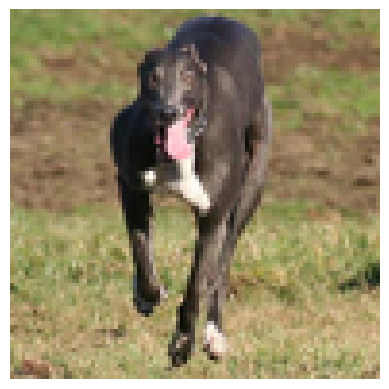

In [419]:
#a dataset sample
import matplotlib.pyplot as plt

image, label = train_ds[1]   # image shape: (C, H, W)

plt.imshow(image.permute(1, 2, 0))  # convert to (H, W, C)
plt.axis("off")
plt.show()

In [420]:
print('num-batches:', len(iter(train_dataloader)), '| batch-shape:', next(iter(train_dataloader))[0].shape)

num-batches: 1640 | batch-shape: torch.Size([64, 3, 96, 96])


In [295]:
def apply_2d_rope(q, k, n_latent_tokens, rope):
    assert q.shape == k.shape, 'q and k shapes must match'

    B, H, T, D = q.shape

    assert D % 4 == 0, 'head size must be divisible by 4'

    row_cos, row_sin, col_cos, col_sin = rope
    n_patches = row_cos.shape[0]

    assert T == n_latent_tokens + n_patches

    #match mixed-precision q/k
    row_cos = row_cos.to(dtype=q.dtype)
    row_sin = row_sin.to(dtype=q.dtype)
    col_cos = col_cos.to(dtype=q.dtype)
    col_sin = col_sin.to(dtype=q.dtype)

    def rotate_pairs(x, cos, sin):
        # (B, H, P, D/2)
        x = x.reshape(B, H, n_patches, D//4, 2)

        a, b = x.unbind(dim=-1)

        a_rot = a*cos - b*sin
        b_rot = a*sin + b*cos

        return torch.stack((a_rot, b_rot), dim=-1).flatten(-2)

    def rotate_tensor(x):
        original_T = x.shape[2]

        #latent tokens remain untouched
        x_latent = x[:, :, :n_latent_tokens]
        x_patch = x[:, :, n_latent_tokens:]

        assert x_latent.shape[2] == n_latent_tokens
        assert x_patch.shape[2] == n_patches

        #first half of channels use row position
        #second half of channesl use col position
        x_row, x_col = x_patch.chunk(2,dim=-1)

        x_row = rotate_pairs(x_row, row_cos, row_sin)
        x_col = rotate_pairs(x_col, col_cos, col_sin)

        x_patch = torch.cat((x_row, x_col), dim=-1) #pair up the row and col tokens along D

        x = torch.cat((x_latent, x_patch), dim=2) #stack latent and patch tokens along T
        assert x.shape[2] == original_T, (
            f"RoPE changed token count: {original_T} -> {x.shape[2]}"
        )

        return x

    return rotate_tensor(q), rotate_tensor(k)

In [296]:
#pre-norm multi-head attention
class MHA(nn.Module):
    def __init__(self, 
                 n_heads, 
                 head_size, 
                 emb_dim, 
                 n_latent_tokens
                ):
        super().__init__()

        self.n_heads = n_heads
        self.head_size = head_size
        self.emb_dim = emb_dim
        self.n_latent_tokens = n_latent_tokens

        self.norm = nn.LayerNorm(emb_dim)
        self.QKV = nn.Linear(emb_dim, 3*n_heads * head_size)

        self.out_proj = nn.Linear(n_heads * head_size, emb_dim)

        self.gamma = nn.Parameter(torch.full( (emb_dim,), layer_scale_gamma))

    def forward(self, x, rope):
        residual = x
        
        
        #useful for shape viewing/permuting below
        B, T, C = x.shape
        nh = self.n_heads
        hs = self.head_size

        #normalize
        x = self.norm(x)
        
        qkv = self.QKV(x) # (B, T, C) -> ( B, T, 3 * n_heads *head_size )

        #slice qkv aprt
        q = qkv[:, :, : nh * hs ] # ( B, T, n_heads * head_size )
        k = qkv[:, :, nh * hs : 2 * nh * hs ] # ( B, T, n_heads * head_size )
        v = qkv[:, :, 2 * nh * hs :] # ( B, T, n_heads * head_size )


        
        #reshape (B, T, n_heads*headsize) -> (B, n_heads, T, headsize)
        q = q.view(B, T, nh, hs).permute(0, 2, 1, 3)
        k = k.view(B, T, nh, hs).permute(0, 2, 1, 3)
        v = v.view(B, T, nh, hs).permute(0, 2, 1, 3)

        q, k = apply_2d_rope(
            q,
            k,
            n_latent_tokens=self.n_latent_tokens,
            rope=rope,
        )

        #q @ k.t / head_size **0.5
        wei = q @ k.transpose(-1, -2) / (hs**0.5) # (B, H, qT, kT)

        wei = wei.softmax(dim = -1) # each key dimension should total up to 1

        out = wei@v # (qT, kT) @ (vT, headsize) -> (B, H, T, headsize)

        out = out.permute(0, 2, 1, 3).flatten(-2) # (B, T, H*hs)

        out = residual + self.gamma * self.out_proj(out) # (B T C)


        return out
        

In [297]:
class MLP(nn.Module):
    def __init__(self, emb_dim):
        super().__init__()

        self.gamma = nn.Parameter(torch.full((emb_dim,), layer_scale_gamma))
        
        self.net = nn.Sequential(
            nn.LayerNorm(emb_dim),
            nn.Linear(emb_dim, emb_dim*4),
            nn.GELU(),
            nn.Linear(emb_dim*4, emb_dim)
        )

    def forward(self, x):
        return x + self.gamma * self.net(x)

In [250]:
#transformer+MLP block
class Block(nn.Module):
    def __init__(self, 
                 n_heads, 
                 head_size, 
                 emb_dim,
                 n_latent_tokens):
        super().__init__()

        self.MHA = MHA(n_heads, head_size, emb_dim, n_latent_tokens)
        self.MLP = MLP(emb_dim)

    def forward(self, x, rope):

        x = self.MHA(x, rope)
        
        x = self.MLP(x)

        return x
        

In [251]:
class PatchEmbed(nn.Module):
    def __init__(self, patch_size, c, emb_dim):
        super().__init__()

        self.patch_size = patch_size

        self.embed = nn.Conv2d(in_channels = c,
                             out_channels = emb_dim,
                             kernel_size = patch_size,
                             stride = patch_size,
                             padding=0)


    def forward(self, x):
        B, C, H, W = x.shape
        patch_rows = H//patch_size
        patch_cols = W//patch_size

        
        out = self.embed(x) # (B, C, H, W) -> (B, emb_dim, pr, pc)
        out = out.flatten(-2).permute(0, 2, 1) # (B, T, C)

        return out, patch_rows, patch_cols

In [252]:
class PatchUnEmbed(nn.Module):
    def __init__(self, patch_size, c, emb_dim):
        super().__init__()

        self.patch_size = patch_size
        self.c = c
        self.emb_dim = emb_dim

        self.to_pixels = nn.Linear(emb_dim, c * patch_size**2)

    def forward(self, x, patch_rows, patch_cols):
        B, T, C = x.shape
        p = self.patch_size
        c = self.c

        x = self.to_pixels(x) # BTC -> B, T, c*p**2

        # Split token position and patch contents
        # (B, pr, pc, c, patch, patch)

        x = x.reshape(B,  patch_rows, patch_cols, c, p, p)

        # Interleave patch-grid and within-patch coordinates
        # (B, c, pr, patch, pc, patch)
        x = x.permute(0, 3, 1, 4, 2, 5)

        # Join them into image height and width
        # (B, c, pr*p, pc*p) 
        out = x.reshape(B, c, patch_rows*p, patch_cols*p)

        return out




In [253]:
#define core transformer model 

class CoreTransformer(nn.Module):
    def __init__(self, 
                 emb_dim, 
                 num_blocks, 
                 n_heads, 
                 head_size, 
                 n_latent_tokens
                ):
        
        super().__init__()

        self.n_latent_tokens = n_latent_tokens

        self.blocks = nn.ModuleList([
            Block(n_heads, head_size, emb_dim, n_latent_tokens)
                for _ in range(num_blocks)
        ])
        
        self.norm = nn.LayerNorm(emb_dim)

        #ROPE BUFFER
        pair_idx = torch.arange(head_size//4, dtype=torch.float32)
        inv_freq = 10_000 ** (-pair_idx / (head_size)//4)

        self.register_buffer("inv_freq", inv_freq, persistent=False)
        self.register_buffer("row_sin_cache", torch.empty(0), persistent=False)
        self.register_buffer("row_cos_cache", torch.empty(0), persistent=False)
        self.register_buffer("col_sin_cache", torch.empty(0), persistent=False)
        self.register_buffer("col_cos_cache", torch.empty(0), persistent=False)

        self.rope_cache_grid = None

    def forward(self, x, patch_rows, patch_cols):
        rope = self.get_rope_cache(patch_rows, patch_cols)
        
        for block in self.blocks:
            x = block(x, rope)

        x = self.norm(x)
    
        return x

    def get_rope_cache(self, patch_rows, patch_cols):
        grid = (patch_rows, patch_cols) #current layout

        if self.rope_cache_grid != grid: #only rebuild when the grid changes
            row_pos = torch.arange(
                patch_rows,
                device = self.inv_freq.device,
            ).repeat_interleave(patch_cols) # rpt interleaved makes pattern e.g. 000111222333 - 000N X cols - 1234...N up to rows

            
            col_pos = torch.arange(
                patch_cols,
                device=self.inv_freq.device,
            ).repeat(patch_rows) # rpt (no interleave) makes pattern e.g. 012301230123 - 0123.0123 X rows - 1234...N up to cols
    
            row_angles = row_pos[:, None] * self.inv_freq[None, :] 
            col_angles = col_pos[:, None] * self.inv_freq[None, :]
    
            self.row_cos_cache = row_angles.cos()
            self.row_sin_cache = row_angles.sin()
            self.col_cos_cache = col_angles.cos()
            self.col_sin_cache = col_angles.sin()
    
            self.rope_cache_grid = grid
        return (
            self.row_cos_cache,
            self.row_sin_cache,
            self.col_cos_cache,
            self.col_sin_cache,
        )

In [254]:
#define encoder model 
from typing import NamedTuple, Optional


class EncoderOutput(NamedTuple):
    z: torch.Tensor
    noise_tokens: Optional[torch.Tensor]
    patch_rows: int
    patch_cols: int
    
class Encoder(nn.Module):
    def __init__(self, 
                 patch_size, 
                 in_channels, 
                 emb_dim, 
                 num_blocks, 
                 n_heads, 
                 head_size, 
                 n_latent_tokens
                ):
        
        super().__init__()

        self.n_latent_tokens = n_latent_tokens
        self.emb_dim = emb_dim

        self.out_norm = nn.LayerNorm(emb_dim*n_latent_tokens, elementwise_affine=False) #reconsider affine False w/ z norm

        self.latent_tokens = nn.Parameter(torch.randn((1, n_latent_tokens, emb_dim)))
        
        self.embed = PatchEmbed(patch_size, in_channels, emb_dim)

        self.core_transformer = CoreTransformer(emb_dim = emb_dim, 
                                                 num_blocks = num_blocks, 
                                                 n_heads = n_heads, 
                                                 head_size = head_size, 
                                                 n_latent_tokens = n_latent_tokens
                                                )
    def forward(self, image):
        
        patches, patch_rows, patch_cols = self.embed(image)
        
        # cat latent tokens with patch embed
        B = patches.shape[0]
        
        latents = self.latent_tokens.expand(B, -1, -1)
        x = torch.cat([latents, patches], dim=1)
        
        x = self.core_transformer(x, patch_rows, patch_cols)

        #slice latent tokens out of x
        latents = x[:, :self.n_latent_tokens]

        patches = x[:, self.n_latent_tokens:]

        #removing out norm in favor of SIGReg loss
        #latents = self.out_norm(latents.flatten(start_dim=1)).reshape_as(latents)

        return EncoderOutput(
            latents, 
            patches, 
            patch_rows, 
            patch_cols
        )

In [176]:
#define decoder model 

class Decoder(nn.Module):
    def __init__(self, 
                 patch_size, 
                 out_channels, 
                 emb_dim, 
                 num_blocks, 
                 n_heads, 
                 head_size, 
                 n_latent_tokens
                ):
        
        super().__init__()

        self.n_latent_tokens = n_latent_tokens

        self.learned_patch_token = nn.Parameter(torch.randn((1,1,emb_dim)))

        self.latent_slots = nn.Parameter(
            torch.randn(1, n_latent_tokens, emb_dim) * 0.02
        )
        
        self.un_embed = PatchUnEmbed(patch_size = patch_size, 
                                     c = out_channels, 
                                     emb_dim = emb_dim)

        self.core_transformer = CoreTransformer(emb_dim = emb_dim, 
                                                 num_blocks = num_blocks, 
                                                 n_heads = n_heads, 
                                                 head_size = head_size, 
                                                 n_latent_tokens = n_latent_tokens
                                                )

        
    def forward(self, enc):
        latents = enc.z + self.latent_slots
        patch_rows = enc.patch_rows
        patch_cols = enc.patch_cols


        #x( B, n_latent_tokens, emb_dim)
        B, T, C = latents.shape

        #copy from (emb_dim) to (B(broadcast), patches*patches(broadcast), emb_dim)
        patches = self.learned_patch_token.expand(B, patch_rows*patch_cols, -1)  
        
        x = torch.cat([latents, patches], dim=1) # cat along token axis

        x = self.core_transformer(x, patch_rows, patch_cols)

        
        #slice patch tokens out of x
        patch_embeddings = x[:, self.n_latent_tokens:]
 
        images = torch.sigmoid(self.un_embed(patch_embeddings, patch_rows, patch_cols))


        return images

In [177]:
class ImageDiscriminator(nn.Module):
    def __init__(self, in_channels, emb_dim, patch_size):
        super().__init__()
        self.patch_size = patch_size

        self.net = nn.Sequential(
            nn.Conv2d(in_channels, emb_dim, kernel_size = 3, padding=1),
            nn.LeakyReLU(0.1),

            nn.Conv2d(emb_dim, emb_dim*2, kernel_size = 3, padding=1),
            nn.LeakyReLU(0.1),

            nn.Conv2d(emb_dim*2, emb_dim*4, kernel_size = 3, padding=1),
            nn.LeakyReLU(0.1),

            nn.Conv2d(emb_dim*4, 1, kernel_size = 1, padding=0),
        )
    def forward(self, x):
        x = self.net(x)

        x = F.avg_pool2d(
            x,
            kernel_size = self.patch_size,
            stride=self.patch_size,
        )

        return x

In [178]:
def sliced_wasserstein_distance(z, prior, n_slices = 16):
    assert z.shape == prior.shape

    z = z.flatten(1) #(B, D)
    prior = prior.flatten(1) #(B, D)

    B, D = z.shape

    slices = F.normalize(
        torch.randn(D, n_slices, device=z.device, dtype=z.dtype),
        dim = 0
    ) # (D, S)

    z_slices, _ = torch.sort(z @ slices, dim=0) # BD @ DS -> BS
    p_slices, _ = torch.sort(prior @ slices, dim=0) # BD @ DS -> BS

    avg_square_distance = torch.mean((z_slices - p_slices)**2)

    avg_square_distance = avg_square_distance.clamp_min(1e-8) #prevent small number crashy when multiplying by swd loss weight

    return avg_square_distance
    

In [ ]:
def basis_wasserstein_distance(z, prior):
    assert z.shape == prior.shape

    z = z.flatten(1)       # (B, D)
    prior = prior.flatten(1)  # (B, D)

    # each D coordinate is one basis direction
    z_basis, _ = torch.sort(z, dim=0)        # sort across B
    p_basis, _ = torch.sort(prior, dim=0)    # sort across B

    avg_square_distance = torch.mean((z_basis - p_basis) ** 2)

    avg_square_distance = avg_square_distance.clamp_min(1e-8)

    return avg_square_distance

In [179]:
def SIGReg(z, n_slices=16):
    #sigreg loss
    #each emb should be unit gaussian across the batch

    B, T, C = z.shape

    z = z.flatten(1) # BD

    slice_dirs = torch.randn((T*C, n_slices), device=z.device, dtype=z.dtype) # DN
    slice_dirs = F.normalize(slice_dirs, dim=0) 

    slices = z@slice_dirs #BN

    t = torch.linspace(0, 5, 9, device=z.device, dtype=z.dtype) # frequencies, aka 't' : 9 points spaced evenly between 0 and 5

    sin_responses = torch.sin( t*slices[...,None] ).mean(dim=0) # t * BN1 -- broadcasts BN1 across t for BNt, then reduce B with mean
    cos_responses = torch.cos( t*slices[...,None] ).mean(dim=0) # t * BN1 -- broadcasts BN1 across t for BNt

    sin_target = torch.zeros_like(sin_responses)
    cos_target = torch.exp(-0.5*t**2).expand_as(cos_responses) # t
    weights = torch.exp(-0.5*t**2) # also t.  this weights the losses by a gaussian 

    sin_loss = F.mse_loss(sin_responses, sin_target, reduction="none")*weights # BNt 1   * t -> BNt
    cos_loss = F.mse_loss(cos_responses, cos_target, reduction="none")*weights # BNt t   * t -> BNt


    SIGReg_loss = 0.5*(sin_loss.mean() + cos_loss.mean())

    return SIGReg_loss

    

In [180]:
def z_batch_variance_loss(z):
    var = z.var(dim=0, correction=0)

    loss = (
        var
        - torch.log(var + 1e-8)
        - 1
    ).mean()

    return loss

In [181]:
def laplacian(x):
    C = x.shape[1]

    kernel = torch.tensor(
        [[0, -1,  0],
         [-1, 4, -1],
         [0, -1,  0]],
        device=x.device,
        dtype=x.dtype,
    )

    kernel = kernel[None, None].repeat(C, 1, 1, 1)

    return F.conv2d(x, kernel, padding=1, groups=C)

In [182]:
#helper: def render reconstruction
@torch.no_grad()
def render_reconstruction(close_fig = False):
    train_iter = iter(train_dataloader)
    features, labels = next(train_iter)
    features = features.to(device)
    x_hat = decoder(encoder(features))

    x = features[1].detach().cpu().permute(1, 2, 0)
    recon = x_hat[1].detach().cpu().permute(1, 2, 0)
    #recon = x_hat[0,0]

    fig, axs = plt.subplots(1, 2, figsize = (6,3))

    axs[0].imshow(x)
    axs[0].set_title('input')
    axs[0].axis('off')

    
    axs[1].imshow(recon)
    axs[1].set_title('reconstruction')
    axs[1].axis('off')

    if close_fig:
        plt.close(fig)

In [183]:
#helper: def plot_training_snapshot
import os
import torch
import matplotlib.pyplot as plt


@torch.no_grad()
def plot_training_snapshot(
    recon_targets,
    step,
    total_steps,
    save_path=None,
    show=False,
):
    """
    Plot four fixed reconstruction examples.

    Row 1: original targets
    Row 2: model reconstructions

    Assumes:
        recon_targets: (4, C, H, W)
        encoder and decoder exist in the outer scope
    """
    if recon_targets.ndim != 4:
        raise ValueError(
            f"Expected recon_targets shaped (4, C, H, W), "
            f"got {recon_targets.shape}"
        )

    if recon_targets.shape[0] != 4:
        raise ValueError(
            f"Expected exactly 4 reconstruction targets, "
            f"got {recon_targets.shape[0]}"
        )

    # Infer the model device rather than relying on a global `device`.
    model_device = next(encoder.parameters()).device
    targets = recon_targets.to(model_device)

    encoder_was_training = encoder.training
    decoder_was_training = decoder.training

    encoder.eval()
    decoder.eval()

    try:
        reconstructions = decoder(encoder(targets))
    finally:
        encoder.train(encoder_was_training)
        decoder.train(decoder_was_training)

    targets = targets.detach().float().cpu()
    reconstructions = reconstructions.detach().float().cpu()

    if reconstructions.shape != targets.shape:
        raise ValueError(
            "Target and reconstruction shapes do not match:\n"
            f"targets:         {targets.shape}\n"
            f"reconstructions: {reconstructions.shape}"
        )

    def prepare_for_imshow(image):
        """
        Convert:
            (1, H, W) -> (H, W)
            (3, H, W) -> (H, W, 3)
        """
        if image.ndim != 3:
            raise ValueError(
                f"Expected individual image shaped (C, H, W), got {image.shape}"
            )

        channels = image.shape[0]

        if channels == 1:
            return image.squeeze(0).clamp(0, 1).numpy()

        if channels in (3, 4):
            return image.permute(1, 2, 0).clamp(0, 1).numpy()

        raise ValueError(f"Cannot display image with {channels} channels")

    # Per-example reconstruction error for a compact progress signal.
    mse = (
        (targets - reconstructions)
        .square()
        .flatten(start_dim=1)
        .mean(dim=1)
    )

    fig, axes = plt.subplots(
        2,
        4,
        figsize=(12, 6),
        gridspec_kw={
            "hspace": 0.08,
            "wspace": 0.08,
        },
    )

    fig.suptitle(
        f"Autoencoder Training — Step {step:,} / {total_steps:,}",
        fontsize=15,
        y=0.97,
    )

    for i in range(4):
        target = prepare_for_imshow(targets[i])
        reconstruction = prepare_for_imshow(reconstructions[i])

        # Top row: original
        axes[0, i].imshow(
            target,
            cmap="gray" if targets.shape[1] == 1 else None,
            vmin=0,
            vmax=1,
            interpolation="nearest",
        )
        axes[0, i].set_title(
            f"Sample {i + 1}\nMSE: {mse[i].item():.4f}",
            fontsize=10,
        )
        axes[0, i].axis("off")

        # Bottom row: reconstruction
        axes[1, i].imshow(
            reconstruction,
            cmap="gray" if reconstructions.shape[1] == 1 else None,
            vmin=0,
            vmax=1,
            interpolation="nearest",
        )
        axes[1, i].axis("off")

    # Shared row labels avoid repeating eight titles.
    fig.text(
        0.025,
        0.69,
        "Target",
        rotation=90,
        va="center",
        ha="center",
        fontsize=12,
    )
    fig.text(
        0.025,
        0.29,
        "Reconstruction",
        rotation=90,
        va="center",
        ha="center",
        fontsize=12,
    )

    fig.subplots_adjust(
        top=0.86,
        bottom=0.04,
        left=0.06,
        right=0.99,
    )

    if save_path is not None:
        save_dir = os.path.dirname(save_path)

        if save_dir:
            os.makedirs(save_dir, exist_ok=True)

        fig.savefig(
            save_path,
            dpi=120,
            bbox_inches="tight",
        )

    if show:
        plt.show()

    plt.close(fig)

In [184]:
#get split losses
@torch.no_grad()
def get_split_loss(split):
    encoder_was_training = encoder.training
    decoder_was_training = decoder.training

    encoder.eval()
    decoder.eval()
    
    if split == 'test':
        x , _ = next(iter(test_dataloader))
        x = x.to(device)
        
        x_hat = decoder(encoder(x))
        
        loss = F.mse_loss(x, x_hat)

        encoder.train(encoder_was_training)
        decoder.train(decoder_was_training)
        
        return loss
    if split == 'train':
        train_iter = iter(train_dataloader)
        losses = []
        for _ in range(20):
            x , _ = next(train_iter)
            x = x.to(device)

            
            x_hat = decoder(encoder(x))
            loss = F.mse_loss(x, x_hat)
            
            losses.append(loss)

        encoder.train(encoder_was_training)
        decoder.train(decoder_was_training)
        
        return torch.stack(losses).mean()

In [185]:
#log metrics
from collections import defaultdict
from copy import deepcopy

if "logs" not in globals():
    logs = defaultdict(list)


def clear_logs():
    logs.clear()


def log_metrics(**metrics):
    for name, value in metrics.items():
        if value is None:
            continue

        if torch.is_tensor(value):
            value = value.detach().item()

        logs[name].append(value)


def get_metrics():
    return {
        name: history[-1]
        for name, history in logs.items()
        if history
    }

def get_metrics_lists():
    return {
        name: history.copy()
        for name, history in logs.items()
        if history
    }

In [186]:
from copy import deepcopy
from pathlib import Path
import torch
from datetime import datetime

RUN_DIR = Path("training_runs")
RUN_DIR.mkdir(exist_ok=True)

runs = {}
current_run_name = None

def archive_current_run():
    global current_run_name

    if current_run_name is None:
        print('warning: current_run_name is None')
        return

    history = get_metrics_lists()

    if not history.get("recon_loss"):
        return

    history = deepcopy(history)

    runs[current_run_name] = history

    torch.save(
        {"history": history},
        RUN_DIR / f"{current_run_name}.pt"
    )

    print(
        f"archived {current_run_name}: "
        f"{len(history['recon_loss']):,} steps"
    )

def start_run(name):
    global current_run_name

    archive_current_run()
    clear_logs()

    timestamp = datetime.now().strftime("%Y-%m-%d_%H%M")    
    current_run_name = f"{timestamp}_{name}"

    print(f"started run: {current_run_name}")

In [187]:
def start_z_gradient_diagnostics(enc, sigreg_loss, variance_loss):
    if not TRACK_Z_DIAGNOSTICS:
        return None

    enc.z.retain_grad()

    g_sigreg = torch.autograd.grad(
        sigreg_weight * sigreg_loss,
        enc.z,
        retain_graph=True,
    )[0].detach()

    g_variance = torch.autograd.grad(
        variance_weight * variance_loss,
        enc.z,
        retain_graph=True,
    )[0].detach()

    return {
        "g_sigreg": g_sigreg,
        "g_variance": g_variance,
    }

def finish_z_gradient_diagnostics(enc, diagnostic):
    if diagnostic is None:
        return {}

    with torch.no_grad():
        g_total = enc.z.grad

        g_sigreg = diagnostic["g_sigreg"]
        g_variance = diagnostic["g_variance"]

        # total = recon + sigreg + variance
        g_recon = g_total - g_sigreg - g_variance

        recon_rms = g_recon.square().mean().sqrt()

        grad_ratio = (
            g_sigreg.square().mean().sqrt()
            / (recon_rms + 1e-12)
        )

        variance_ratio = (
            g_variance.square().mean().sqrt()
            / (recon_rms + 1e-12)
        )

    return {
        "grad_ratio": grad_ratio,
        "variance_ratio": variance_ratio,
    }

In [188]:
def align_sigreg_grad(g_recon, g_sig, mode="plain", eps=1e-8):
    """
    Shape SIGReg's gradient relative to reconstruction.
    Projection is per image over the full latent [T, C].
    """
    shape = g_sig.shape

    gr = g_recon.flatten(1)
    gs = g_sig.flatten(1)

    # signed amount of SIGReg gradient parallel to recon gradient
    c = (
        (gs * gr).sum(dim=1, keepdim=True)
        / gr.square().sum(dim=1, keepdim=True).clamp_min(eps)
    )

    g_parallel = c * gr
    g_perp = gs - g_parallel

    if mode == "plain":
        out = gs

    elif mode == "sovereign":
        # SIGReg gets only directions locally neutral to recon
        out = g_perp

    elif mode == "protected":
        # remove only anti-recon parallel component
        out = gs - c.clamp(max=0) * gr

    elif mode == "reinforce":
        # keep only parallel component that helps recon
        out = c.clamp(min=0) * gr

    else:
        raise ValueError(f"unknown mode: {mode}")

    return out.view(shape)

In [189]:
# --------------------Def Init Models (and optimizers) --------------------


def init_models():
    
    encoder = Encoder(
        patch_size,
        c,
        emb_dim,
        num_blocks,
        n_heads,
        head_size,
        n_latent_tokens,
    )
    
    decoder = Decoder(
        patch_size,
        c,
        emb_dim,
        num_blocks,
        n_heads,
        head_size,
        n_latent_tokens,
    )
    
    
    device = "cuda" if torch.cuda.is_available() else "cpu"
    
    encoder.to(device)
    decoder.to(device)
    
    
    # -------------------- Optimizers --------------------
    
    ae_parameters = (
        list(encoder.parameters())
        + list(decoder.parameters())
    )
    n_ae_parameters  = sum(p.numel() for p in ae_parameters)
    print(f"{n_ae_parameters:,} ae parameters")
    
    ae_optimizer = torch.optim.AdamW(
        ae_parameters,
        lr=lr,
    )

    return (
        encoder,
        decoder,
        ae_optimizer,
        device,
    )


In [421]:
######################################################################################################################################
############################################################ init models #############################################################
######################################################################################################################################
SEED = 42

torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
train_generator.manual_seed(DATA_SEED)

start_run("ae_1M_align_sigreg_grad_"+sigreg_grad_mode)

(
    encoder,
    decoder,
    ae_optimizer,
    device,
) = init_models()
torch._functorch.config.donated_buffer = not TRACK_Z_DIAGNOSTICS
encoder = torch.compile(encoder)
# decoder = torch.compile(decoder) # decoder must not be compiled for autograd stuff to work


archived 2026-09-04_1546_ae_1M_align_sigreg_grad_protected: 41,000 steps
started run: 2026-09-04_1624_ae_1M_align_sigreg_grad_reinforce
986,352 ae parameters


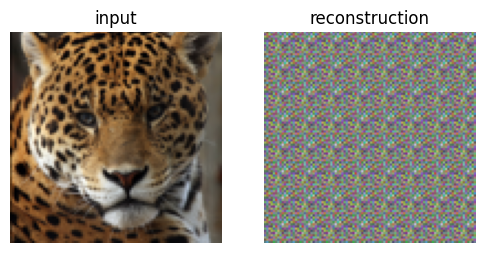

In [422]:
render_reconstruction() #test model recon

In [423]:
################## Training Step Methods ########################
from torch.profiler import record_function

def train_step_simple(images):
    images = images.to(device)

    #forward
    enc = encoder(images)
    x_hat = decoder(enc)

    #zero grad
    ae_optimizer.zero_grad(set_to_none=True)

    #losses
    recon_loss = F.mse_loss(images, x_hat)

    sigreg_loss = SIGReg(enc.z)

    variance_loss = z_batch_variance_loss(enc.z)

    image_highfreq = laplacian(images)
    recon_highfreq = laplacian(x_hat)
    
    laplacian_loss = F.mse_loss(recon_highfreq, image_highfreq)


    #combine losses
    ae_loss = ( 
        recon_loss
        + sigreg_loss * sigreg_weight
        + variance_loss * variance_weight
        + laplacian_loss * laplacian_weight
    )

    # diagnostic: relative pressure at z
    diagnostic = start_z_gradient_diagnostics(
        enc,
        sigreg_loss,
        variance_loss,
    )


    #aligned sigreg loss
    g_recon = torch.autograd.grad(
        recon_loss,
        enc.z,
        retain_graph=True,
        create_graph=False,
    )[0].detach()
    
    g_sig = torch.autograd.grad(
        sigreg_loss,
        enc.z,
        retain_graph=True,
        create_graph=False,
    )[0].detach()
    
    g_sig_aligned = align_sigreg_grad(
        g_recon,
        g_sig,
        mode=sigreg_grad_mode
    )
    
    grad_delta = sigreg_weight * (g_sig_aligned - g_sig)
    
    enc.z.register_hook(lambda grad: grad + grad_delta)

    
    # real backward: decoder backward happens only once
    ae_loss.backward()

    # diagnostic: relative pressure at z
    diagnostic_metrics = finish_z_gradient_diagnostics(
        enc,
        diagnostic,
    )
    
    # parameter update
    ae_optimizer.step()

    zero = recon_loss.new_zeros(())

    log_metrics(
        ae_loss=ae_loss,
        recon_loss=recon_loss,
        sigreg_loss=sigreg_loss,
        variance_loss=variance_loss,
        laplacian_loss=laplacian_loss,
        **diagnostic_metrics,
    )
    
    return get_metrics()



In [424]:
# #OVERFIT MICRO-BATCH
# num_epochs = 2
# fixed_micro_batch_size = 6
# fixed_micro_batch = next(iter(train_dataloader))[0][:fixed_micro_batch_size].to(device)

# encoder.train()
# decoder.train()

# report_every = 500

# report_start = time.perf_counter()

# train_loss = get_split_loss('train')
# test_loss = get_split_loss('test')

# print(f'START TRAINING | recon-train-loss:{train_loss:.5f}  recon-test-loss: {test_loss:.5f}')

# for epoch in range(num_epochs): 
#     for batch_step, (images, _) in enumerate(train_dataloader):

#         total_steps = epoch*batches_per_epoch + batch_step

#         metrics = train_step_simple(fixed_micro_batch)

#         if ((total_steps+1) % report_every) == 0:

#             elapsed = time.perf_counter() - report_start
#             sec_per_step = elapsed / report_every
#             samples_per_sec = images.shape[0] / sec_per_step

#             report_start = time.perf_counter()

#             print(
#                 f"\nstep {total_steps + 1} | "
#                 f"{sec_per_step * 1000:.0f} ms/step | "
#                 f"{samples_per_sec:.1f} samples/s | "
#                 f"{len(train_dataloader) * sec_per_step / 60:.1f} min/epoch "

#                 f" --- GPU alloc={torch.cuda.memory_allocated()/1e9:.2f} GB | "
#                 f"reserved={torch.cuda.memory_reserved()/1e9:.2f} GB | "
#                 f"peak={torch.cuda.max_memory_allocated()/1e9:.2f} GB"
#             )
            
#             print(
#                 f"AE:"
#                 f" total={metrics['ae_loss']:.5f}"
#                 f" | recon={metrics['recon_loss']:.5f}"
#                 f" | sigreg={metrics['sigreg_loss']:.5f}"
#                 f" | r/s-ratio={metrics['grad_ratio']:.5f}"
#                 f" | variance={metrics['variance_loss']:.5f}"
#             )


#     #render_reconstruction()
#     train_loss = get_split_loss('train')
#     test_loss = get_split_loss('test')
#     print(' ')
#     print('--------------------------------------------------------------')
#     print(f'EPOCH:{epoch} | recon-train-loss:{train_loss:.5f}  recon-test-loss: {test_loss:.5f}')
#     print('--------------------------------------------------------------')


      

In [731]:
## MAIN TRAINING LOOP #

num_epochs = 300


encoder.train()
decoder.train()

report_every = 500

report_start = time.perf_counter()

train_loss = get_split_loss('train')
test_loss = get_split_loss('test')

print(f'START TRAINING | recon-train-loss:{train_loss:.5f}  recon-test-loss: {test_loss:.5f}')

for epoch in range(num_epochs): 
    for batch_step, (images, _) in enumerate(train_dataloader):

        total_steps = epoch*batches_per_epoch + batch_step

        metrics = train_step_simple(images)

        if ((total_steps+1) % report_every) == 0:

            elapsed = time.perf_counter() - report_start
            sec_per_step = elapsed / report_every
            samples_per_sec = images.shape[0] / sec_per_step

            report_start = time.perf_counter()

            print(
                f"\nstep {total_steps + 1} | "
                f"{sec_per_step * 1000:.0f} ms/step | "
                f"{samples_per_sec:.1f} samples/s | "
                f"{len(train_dataloader) * sec_per_step / 60:.1f} min/epoch "

                # f" --- GPU alloc={torch.cuda.memory_allocated()/1e9:.2f} GB | "
                # f"reserved={torch.cuda.memory_reserved()/1e9:.2f} GB | "
                # f"peak={torch.cuda.max_memory_allocated()/1e9:.2f} GB"
            )
            
            msg = (
                f"AE:"
                f" total={metrics['ae_loss']:.5f}"
                f" | recon={metrics['recon_loss']:.5f}"
                f" | sigreg={metrics['sigreg_loss']:.5f}"
                f" | variance={metrics['variance_loss']:.5f}"
                f" | laplacian={metrics['laplacian_loss']:.5f}"
            )
            
            if TRACK_Z_DIAGNOSTICS:
                msg += (
                    f" | s/r-ratio={metrics['grad_ratio']:.5f}"
                    f" | v/r-ratio={metrics['variance_ratio']:.5f}"
                )
            
            print(msg)


    #render_reconstruction()
    train_loss = get_split_loss('train')
    test_loss = get_split_loss('test')
    print(' ')
    print('--------------------------------------------------------------')
    print(f'EPOCH:{epoch} | recon-train-loss:{train_loss:.5f}  recon-test-loss: {test_loss:.5f}')
    print('--------------------------------------------------------------')

START TRAINING | recon-train-loss:0.00341  recon-test-loss: 0.00332

step 500 | 97 ms/step | 1316.6 samples/s | 1.3 min/epoch 
AE: total=0.01699 | recon=0.00310 | sigreg=0.01786 | variance=0.00019 | laplacian=0.02703 | s/r-ratio=0.01637 | v/r-ratio=0.00573
 
--------------------------------------------------------------
EPOCH:0 | recon-train-loss:0.00330  recon-test-loss: 0.00331
--------------------------------------------------------------

step 2000 | 130 ms/step | 988.0 samples/s | 1.8 min/epoch 
AE: total=0.01634 | recon=0.00302 | sigreg=0.01918 | variance=0.00019 | laplacian=0.02585 | s/r-ratio=0.01594 | v/r-ratio=0.00604
 
--------------------------------------------------------------
EPOCH:1 | recon-train-loss:0.00332  recon-test-loss: 0.00332
--------------------------------------------------------------

step 3500 | 131 ms/step | 980.8 samples/s | 1.8 min/epoch 
AE: total=0.01758 | recon=0.00316 | sigreg=0.01938 | variance=0.00046 | laplacian=0.02797 | s/r-ratio=0.01662 | v/r

KeyboardInterrupt: 

In [732]:
history = get_metrics_lists()


steps = len(history['recon_loss'])
steps_per_epoch = len(train_dataloader)

epochs = steps / steps_per_epoch

print(f"steps:           {steps:,}")
print(f"steps / epoch:   {steps_per_epoch:,}")
print(f"epochs trained:  {epochs:.2f}")

steps:           636,862
steps / epoch:   820
epochs trained:  776.66


In [733]:
## plot decoded images from list of seeds
@torch.no_grad()
def plot_constructions(seeds):
    was_training = decoder.training
    decoder.eval()

    n = seeds.shape[0]
    constructs = decoder(
        EncoderOutput(
            seeds.to(device),
            None,
            patch_rows,
            patch_cols
        )
    ).cpu()

    fig, axes = plt.subplots(1, n, figsize=(n * 2, 4))

    # Weight of the ending latent at each step
    alphas = torch.linspace(0, 1, n)

    for i, (ax, construct) in enumerate(zip(axes.flatten(), constructs)):

        
        
        ax.imshow(
            construct.permute(1, 2, 0),
            vmin=0,
            vmax=1
        )
        ax.axis("off")

        if i == 0:
            label = "Dataset reconstruction\nStart"
        elif i == n - 1:
            label = "Dataset reconstruction\nEnd"
        else:
            label = f"Latent interpolation\nα = {alphas[i]:.2f}"

        ax.set_title(label, fontsize=10)

    fig.suptitle("Linear interpolation through latent space", fontsize=14)
    plt.tight_layout()
    plt.show()

    decoder.train(was_training)


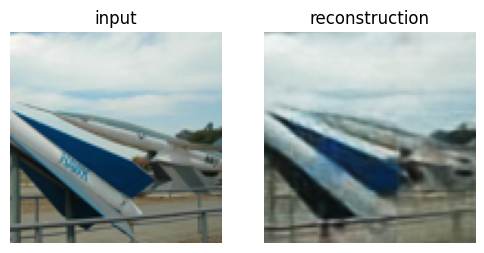

In [734]:
render_reconstruction()

In [735]:
# interpolate two images
def interpolate_two_images():
    train_iter = iter(train_dataloader)
    features, labels = next(train_iter)
    features = features.to(device)[:2]
    z ,_, _ , _ = encoder(features)
    
    z1, z2 = z.unbind(dim=0)
    # _ , z2 = z.unbind(dim=0)
    
    # z1 = torch.randn(n_latent_tokens, emb_dim).to(device)
    # z2 = torch.randn(n_latent_tokens, emb_dim).to(device)
    
    steps = 7
    weights = torch.linspace(0, 1, steps).to(device)
    
    rho = F.cosine_similarity(
        z1.flatten(),
        z2.flatten(),
        dim=0
    )
    
    z_interpolated = torch.stack([
        torch.lerp(z1, z2, a)
        / torch.sqrt(
            (1-a)**2
            + a**2
            + 2*a*(1-a)*rho
        )
        for a in weights
    ])
    
    plot_constructions(z_interpolated)

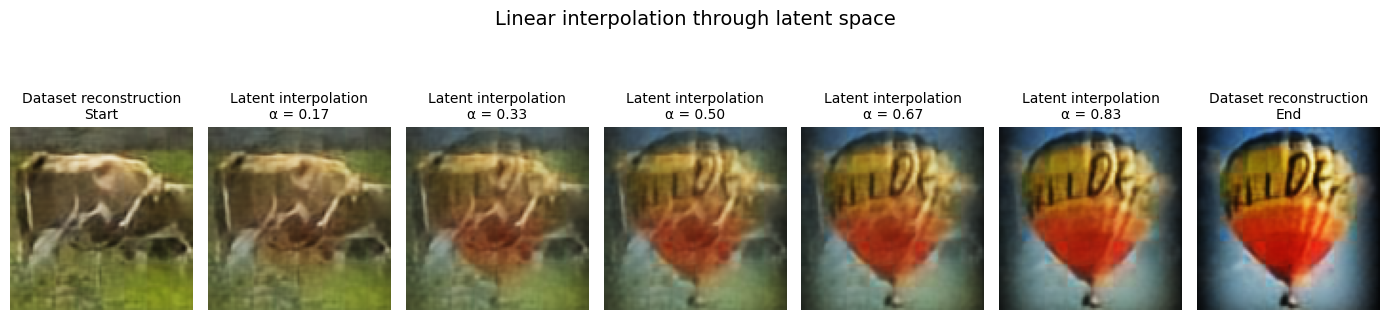

In [764]:
interpolate_two_images()

pairs:  2,016
mean:   0.039
std:    0.672
min:    -0.929
median: 0.039
max:    0.999


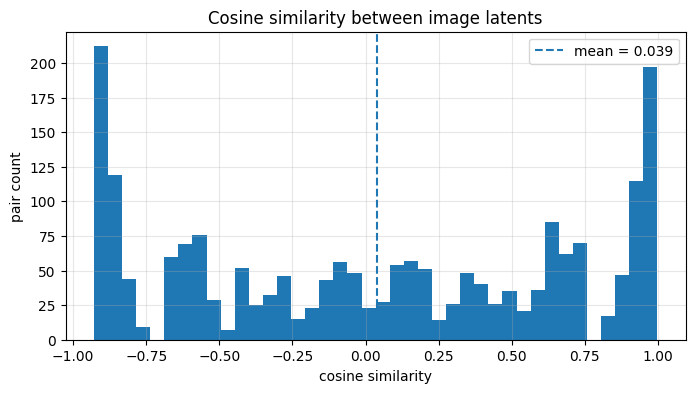

In [670]:
# cosine similarity distribution between unrelated encoded images

import torch
import matplotlib.pyplot as plt

encoder.eval()

with torch.no_grad():
    features, _ = next(iter(train_dataloader))
    features = features.to(device)

    z, _, _, _ = encoder(features)      # [B, T, C]

    # treat each image's whole latent as one vector
    z_flat = z.flatten(1)               # [B, T*C]
    z_flat = torch.nn.functional.normalize(z_flat, dim=1)

    # cosine similarity of every image pair
    cosine_matrix = z_flat @ z_flat.T   # [B, B]

    # keep each unique pair once, excluding self-similarity
    mask = torch.triu(
        torch.ones_like(cosine_matrix, dtype=torch.bool),
        diagonal=1
    )

    cosines = cosine_matrix[mask].cpu()


print(f"pairs:  {len(cosines):,}")
print(f"mean:   {cosines.mean():.3f}")
print(f"std:    {cosines.std():.3f}")
print(f"min:    {cosines.min():.3f}")
print(f"median: {cosines.median():.3f}")
print(f"max:    {cosines.max():.3f}")


plt.figure(figsize=(8, 4))
plt.hist(cosines.numpy(), bins=40)
plt.axvline(cosines.mean(), linestyle="--", label=f"mean = {cosines.mean():.3f}")
plt.xlabel("cosine similarity")
plt.ylabel("pair count")
plt.title("Cosine similarity between image latents")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [767]:
# Check whether a few directions dominate image-to-image latent variation
def latent_pca():
    import torch
    import matplotlib.pyplot as plt
    
    with torch.no_grad():
        x = z.detach().flatten(1).float()       # [B, T*C], not normalized
        x = x - x.mean(dim=0, keepdim=True)     # remove the shared mean vector
    
        if min(x.shape) < 2:
            raise ValueError("Need at least two images and two latent coordinates.")
    
        u, s, _ = torch.linalg.svd(x, full_matrices=False)
        energy = s.square()
    
        if energy.sum().item() == 0:
            raise ValueError("All image latents are identical in this batch.")
    
        # Centering leaves at most B-1 independent directions
        n = min(x.shape[0] - 1, x.shape[1])
        share = (energy[:n] / energy.sum()).cpu()
        cumulative = share.cumsum(0)
        scores = (u[:, :2] * s[:2]).cpu()       # image positions along PC1 and PC2
    
        effective_dims = 1 / share.square().sum()
        dims_90 = torch.searchsorted(cumulative, 0.90).item() + 1
    
    print(f"Images: {x.shape[0]} | Flattened dimensions: {x.shape[1]:,}")
    print(f"Top direction: {share[0]:.1%} of centered variation")
    print(f"Top 2 directions: {share[:2].sum():.1%}")
    print(f"Top 5 directions: {share[:5].sum():.1%}")
    print(f"Directions needed for 90%: {dims_90}")
    print(f"Effective dimensions (participation ratio): {effective_dims:.1f}")
    print(f"Batch can reveal at most {n} independent directions.")
    
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    
    k = min(20, n)
    axes[0].bar(range(1, k + 1), 100 * share[:k].numpy())
    axes[0].set(
        title="Variation carried by each direction",
        xlabel="Principal direction",
        ylabel="Share of variation (%)",
    )
    
    axes[1].plot(range(1, n + 1), 100 * cumulative.numpy())
    axes[1].axhline(90, color="gray", linestyle="--", label="90%")
    axes[1].set(
        title="Cumulative variation",
        xlabel="Number of directions",
        ylabel="Variation captured (%)",
        ylim=(0, 102),
    )
    axes[1].legend()
    
    axes[2].scatter(scores[:, 0], scores[:, 1], s=28, alpha=0.65)
    axes[2].axhline(0, color="gray", linewidth=0.7)
    axes[2].axvline(0, color="gray", linewidth=0.7)
    axes[2].set(
        title="Each dot is one image",
        xlabel=f"PC1 ({share[0]:.1%})",
        ylabel=f"PC2 ({(energy[1] / energy.sum()).item():.1%})",
    )
    axes[2].set_aspect("equal", adjustable="box")
    
    for ax in axes:
        ax.grid(alpha=0.2)
    
    plt.tight_layout()
    plt.show()

Images: 128 | Flattened dimensions: 3,072
Top direction: 98.3% of centered variation
Top 2 directions: 98.8%
Top 5 directions: 99.2%
Directions needed for 90%: 1
Effective dimensions (participation ratio): 1.0
Batch can reveal at most 127 independent directions.


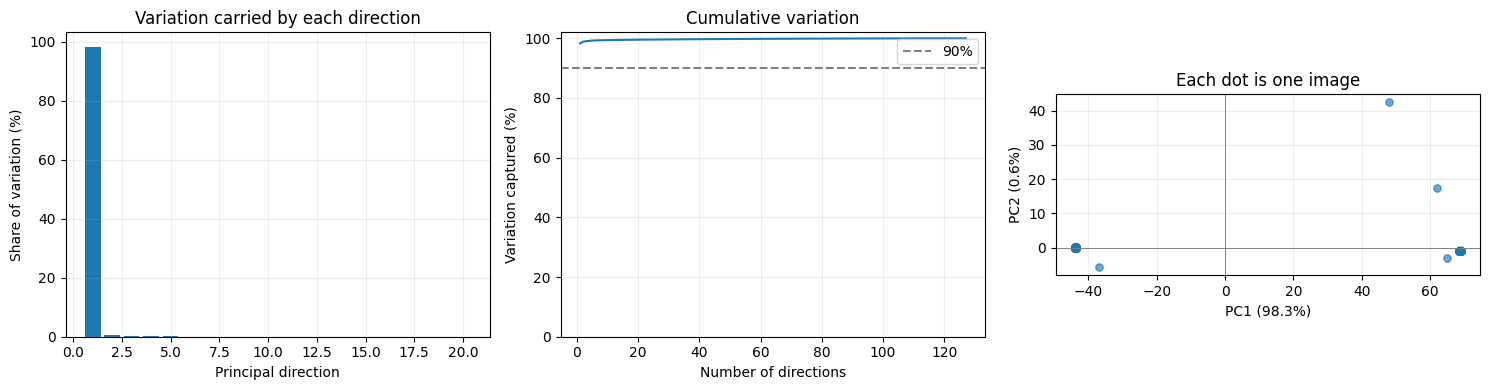

In [768]:
latent_pca()

In [770]:
# Decode full latents, latents without PC1, and PC1 alone
import torch
import matplotlib.pyplot as plt
def decode_pc1():
    encoder.eval()
    decoder.eval()
    
    with torch.no_grad():
        images, _ = next(iter(train_dataloader))
        images = images.to(device)
    
        enc = encoder(images)
        z = enc[0]                                  # [B, T, C]
        x = z.flatten(1).float()
        mean = x.mean(dim=0, keepdim=True)
        centered = x - mean
    
        _, s, vh = torch.linalg.svd(centered, full_matrices=False)
        direction = vh[:1]                          # [1, T*C]
        pc1 = (centered @ direction.T) @ direction  # [B, T*C]
    
        z_without = (mean + centered - pc1).reshape_as(z).to(z.dtype)
        z_only = (mean + pc1).reshape_as(z).to(z.dtype)
    
        # Preserve the encoder output's metadata and container type.
        def with_z(new_z):
            if hasattr(enc, "_replace"):            # namedtuple
                return enc._replace(**{enc._fields[0]: new_z})
            if isinstance(enc, list):
                return [new_z, *enc[1:]]
            return (new_z, *enc[1:])
    
        full = decoder(enc)
        without = decoder(with_z(z_without))
        only = decoder(with_z(z_only))
    
        def mse(a, b):
            return (a.float() - b.float()).square().mean().item()
    
        print(f"PC1 share of centered variation: {(s[0]**2 / s.square().sum()).item():.1%}")
        print("MSE against original images:")
        print(f"  Full latent:   {mse(full, images):.6f}")
        print(f"  Without PC1:   {mse(without, images):.6f}")
        print(f"  Only PC1:      {mse(only, images):.6f}")
        print("MSE against full reconstruction:")
        print(f"  Without PC1:   {mse(without, full):.6f}")
        print(f"  Only PC1:      {mse(only, full):.6f}")
    
    # Assumes images use [0, 1]. Set True if they use [-1, 1].
    images_are_minus1_to1 = False
    
    def display_image(t):
        t = t.detach().float().cpu()
        if images_are_minus1_to1:
            t = (t + 1) / 2
        t = t.clamp(0, 1)
        return t[0].numpy() if t.shape[0] == 1 else t.permute(1, 2, 0).numpy()
    
    n = min(8, len(images))
    rows = [
        ("Original", images),
        ("Full latent", full),
        ("Without PC1\n(mean retained)", without),
        ("Only PC1\n(mean retained)", only),
    ]
    
    fig, axes = plt.subplots(4, n, figsize=(2 * n, 8), squeeze=False)
    
    for row, (label, batch) in enumerate(rows):
        for col in range(n):
            axes[row, col].imshow(display_image(batch[col]), cmap="gray")
            axes[row, col].set_xticks([])
            axes[row, col].set_yticks([])
            if col == 0:
                axes[row, col].set_ylabel(label)
    
    plt.tight_layout()
    plt.show()

PC1 share of centered variation: 98.2%
MSE against original images:
  Full latent:   0.003429
  Without PC1:   0.076453
  Only PC1:      0.069328
MSE against full reconstruction:
  Without PC1:   0.072741
  Only PC1:      0.065591


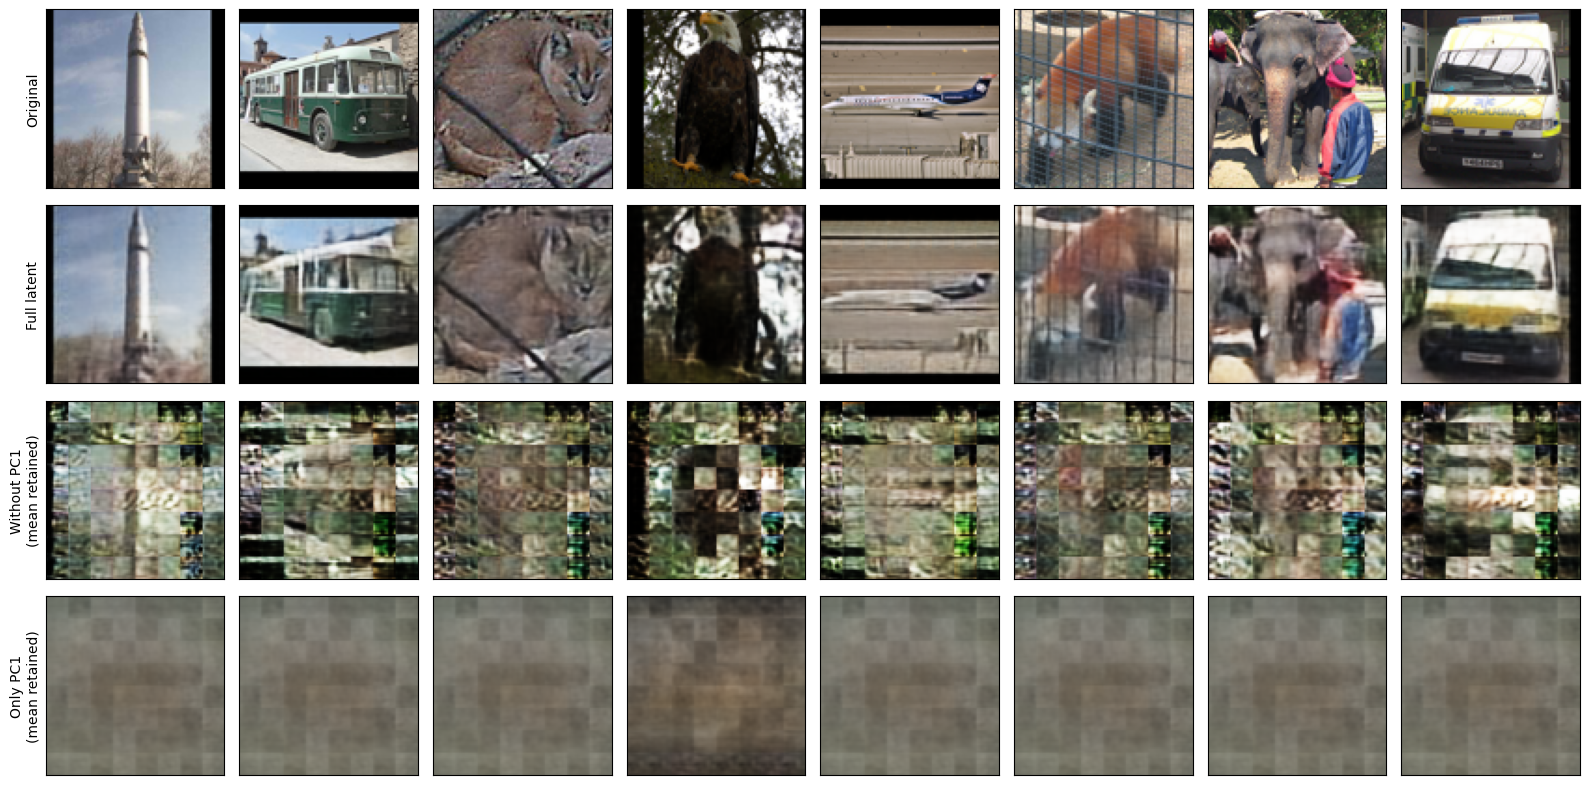

In [771]:
 decode_pc1()

In [772]:
import torch
import matplotlib.pyplot as plt

@torch.no_grad()
def plot_pc1_swap(
    encoder,
    decoder,
    dataloader,
    device,
    n_show=8,
    donor_indices=None,          # default: lowest and highest PC1 scores
    images_are_minus1_to1=False,
):
    encoder_was_training = encoder.training
    decoder_was_training = decoder.training
    encoder.eval()
    decoder.eval()

    try:
        images, _ = next(iter(dataloader))
        images = images.to(device)
        enc = encoder(images)
        z = enc[0]                              # [B, T, C]

        x = z.detach().flatten(1).float()
        if x.shape[0] < 2:
            raise ValueError("Need at least two images.")

        mean = x.mean(0, keepdim=True)
        centered = x - mean
        _, s, vh = torch.linalg.svd(centered, full_matrices=False)

        if s.square().sum().item() == 0:
            raise ValueError("All image latents are identical.")

        direction = vh[:1]                      # [1, T*C]
        scores = centered @ direction.T        # [B, 1]

        if donor_indices is None:
            donor_indices = [
                scores[:, 0].argmin().item(),
                scores[:, 0].argmax().item(),
            ]
        donor_indices = list(dict.fromkeys(int(i) for i in donor_indices))
        if any(i < 0 or i >= len(images) for i in donor_indices):
            raise ValueError("Donor indices must be within this batch.")

        def with_z(new_z):
            if hasattr(enc, "_replace"):
                return enc._replace(**{enc._fields[0]: new_z})
            if isinstance(enc, list):
                return [new_z, *enc[1:]]
            return (new_z, *enc[1:])

        def mse(a, b):
            return (a.float() - b.float()).square().mean().item()

        full = decoder(enc)
        rows = [("Original", images), ("Full latent", full)]
        metrics = []

        for donor in donor_indices:
            # Replace only PC1's coefficient. The donor itself is unchanged.
            swapped_x = x + (scores[donor:donor + 1] - scores) @ direction
            swapped_z = swapped_x.reshape_as(z).to(z.dtype)
            recon = decoder(with_z(swapped_z))

            rows.append((
                f"PC1 from #{donor}\nscore={scores[donor].item():.2f}",
                recon,
            ))
            metrics.append({
                "donor": donor,
                "score": scores[donor].item(),
                "mse_to_images": mse(recon, images),
                "mse_to_full": mse(recon, full),
            })

        # Include donor images among the displayed columns.
        n = min(max(int(n_show), len(donor_indices), 1), len(images))
        shown = donor_indices + [
            i for i in range(len(images)) if i not in donor_indices
        ]
        shown = sorted(shown[:n])

        def display(t):
            t = t.detach().float().cpu()
            if images_are_minus1_to1:
                t = (t + 1) / 2
            t = t.clamp(0, 1)
            return t[0].numpy() if t.shape[0] == 1 else t.permute(1, 2, 0).numpy()

        fig, axes = plt.subplots(
            len(rows), n,
            figsize=(2 * n, 2.2 * len(rows)),
            squeeze=False,
        )
        for r, (label, batch) in enumerate(rows):
            for c, idx in enumerate(shown):
                ax = axes[r, c]
                ax.imshow(display(batch[idx]), cmap="gray", vmin=0, vmax=1)
                ax.set_xticks([])
                ax.set_yticks([])
                if r == 0:
                    ax.set_title(
                        f"Image #{idx}\nPC1={scores[idx].item():.2f}",
                        fontsize=10,
                    )
                if c == 0:
                    ax.set_ylabel(label)

        plt.tight_layout()
        plt.show()

        pc1_share = (s[0].square() / s.square().sum()).item()
        print(f"PC1 share of centered variation: {pc1_share:.1%}")
        print(f"Full reconstruction MSE: {mse(full, images):.6f}")
        for m in metrics:
            print(
                f"Donor #{m['donor']}: "
                f"MSE to images={m['mse_to_images']:.6f} | "
                f"MSE to full={m['mse_to_full']:.6f}"
            )

        return {"pc1_share": pc1_share, "swaps": metrics}

    finally:
        encoder.train(encoder_was_training)
        decoder.train(decoder_was_training)

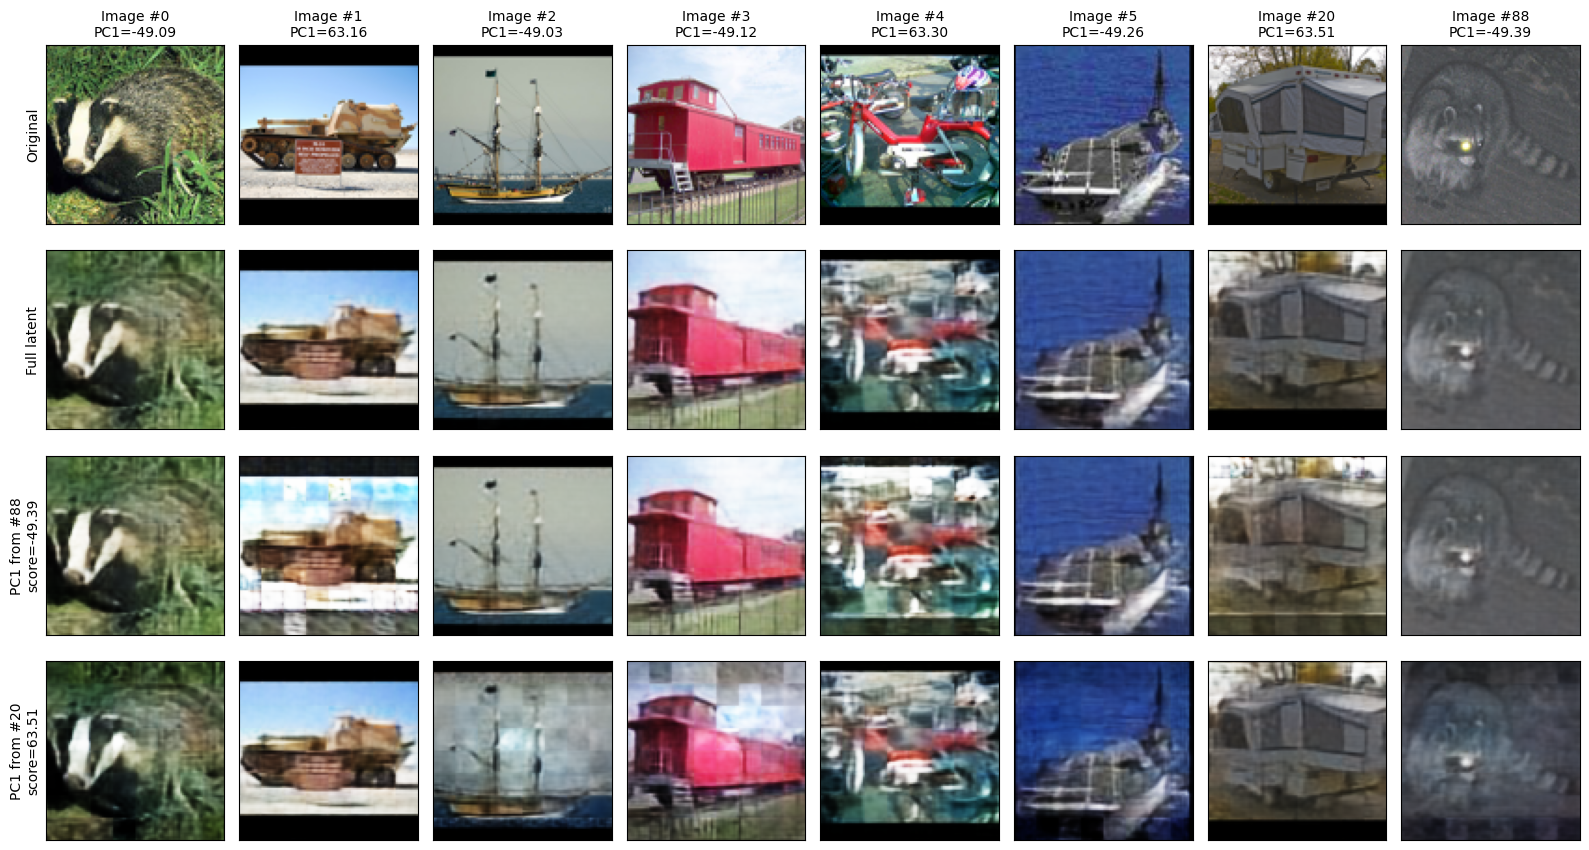

PC1 share of centered variation: 98.7%
Full reconstruction MSE: 0.003396
Donor #88: MSE to images=0.014811 | MSE to full=0.011274
Donor #20: MSE to images=0.015115 | MSE to full=0.011747


In [773]:
pc1_results = plot_pc1_swap(encoder, decoder, train_dataloader, device)

In [774]:
import torch
import matplotlib.pyplot as plt

@torch.no_grad()
def plot_pc1_sweep(
    encoder,
    decoder,
    dataloader,
    device,
    image_indices=None,           # default: lowest and highest PC1 images
    n_steps=9,
    score_range=None,             # default: batch PC1 min/max
    images_are_minus1_to1=False,
):
    encoder_mode, decoder_mode = encoder.training, decoder.training
    encoder.eval()
    decoder.eval()

    try:
        images, _ = next(iter(dataloader))
        images = images.to(device)
        enc = encoder(images)
        z = enc[0]

        x = z.detach().flatten(1).float()
        if len(x) < 2 or n_steps < 2:
            raise ValueError("Need at least two images and two sweep steps.")

        mean = x.mean(0, keepdim=True)
        centered = x - mean
        _, s, vh = torch.linalg.svd(centered, full_matrices=False)
        if s.square().sum().item() == 0:
            raise ValueError("All image latents are identical.")

        direction = vh[:1]
        scores = centered @ direction.T
        remainder = centered - scores @ direction

        if image_indices is None:
            image_indices = [
                scores[:, 0].argmin().item(),
                scores[:, 0].argmax().item(),
            ]
        indices = list(dict.fromkeys(int(i) for i in image_indices))
        if not indices or any(i < 0 or i >= len(x) for i in indices):
            raise ValueError("Choose valid image indices within this batch.")

        lo, hi = (
            (scores.min().item(), scores.max().item())
            if score_range is None else score_range
        )
        if lo >= hi:
            raise ValueError("The score range must have increasing endpoints.")

        # Include zero exactly when it lies within the sweep.
        sweep = torch.linspace(lo, hi, n_steps, device=x.device)
        if lo < 0 < hi:
            sweep = torch.cat([sweep, sweep.new_zeros(1)]).unique(sorted=True)

        def with_z(new_z):
            if hasattr(enc, "_replace"):
                return enc._replace(**{enc._fields[0]: new_z})
            if isinstance(enc, list):
                return [new_z, *enc[1:]]
            return (new_z, *enc[1:])

        full = decoder(enc)
        baseline = full[indices].detach().float().cpu()
        outputs = []

        # Keep the original batch shape and encoder metadata intact.
        for score in sweep:
            modified = z.clone()
            replacements = mean + remainder[indices] + score * direction
            modified[indices] = replacements.reshape(
                len(indices), *z.shape[1:]
            ).to(z.dtype)
            outputs.append(
                decoder(with_z(modified))[indices].detach().float().cpu()
            )

        outputs = torch.stack(outputs, dim=1)    # [images, steps, C, H, W]
        mse_to_full = (
            (outputs - baseline[:, None]).square().flatten(2).mean(2)
        )
        sweep_cpu = sweep.cpu()

        def display(t):
            t = t.detach().float().cpu()
            if images_are_minus1_to1:
                t = (t + 1) / 2
            t = t.clamp(0, 1)
            return t[0].numpy() if t.shape[0] == 1 else t.permute(1, 2, 0).numpy()

        fig, axes = plt.subplots(
            len(indices), len(sweep) + 2,
            figsize=(1.7 * (len(sweep) + 2), 2.3 * len(indices)),
            squeeze=False,
        )

        for r, idx in enumerate(indices):
            row_images = [images[idx], baseline[r], *outputs[r]]
            titles = ["Original", "Full recon"] + [
                f"PC1 = {v:.1f}" for v in sweep_cpu.tolist()
            ]
            for c, (im, title) in enumerate(zip(row_images, titles)):
                ax = axes[r, c]
                ax.imshow(display(im), cmap="gray", vmin=0, vmax=1)
                ax.set_xticks([])
                ax.set_yticks([])
                if r == 0:
                    ax.set_title(title, fontsize=9)
                if c == 0:
                    ax.set_ylabel(
                        f"Image #{idx}\nnative PC1={scores[idx].item():.1f}"
                    )

        plt.tight_layout()
        plt.show()

        fig, ax = plt.subplots(figsize=(7, 3))
        for r, idx in enumerate(indices):
            line, = ax.plot(
                sweep_cpu.numpy(), mse_to_full[r].numpy(),
                marker="o", label=f"Image #{idx}",
            )
            ax.axvline(
                scores[idx].item(), color=line.get_color(),
                linestyle=":", alpha=0.5,
            )
        ax.axvline(0, color="gray", linestyle="--", alpha=0.5)
        ax.set(
            xlabel="PC1 score (dotted lines = native scores)",
            ylabel="MSE to full reconstruction",
            title="Effect of changing PC1 alone",
        )
        ax.legend()
        ax.grid(alpha=0.2)
        plt.tight_layout()
        plt.show()

        return {
            "image_indices": indices,
            "native_scores": scores[indices, 0].cpu(),
            "sweep_scores": sweep_cpu,
            "mse_to_full": mse_to_full,
        }

    finally:
        encoder.train(encoder_mode)
        decoder.train(decoder_mode)

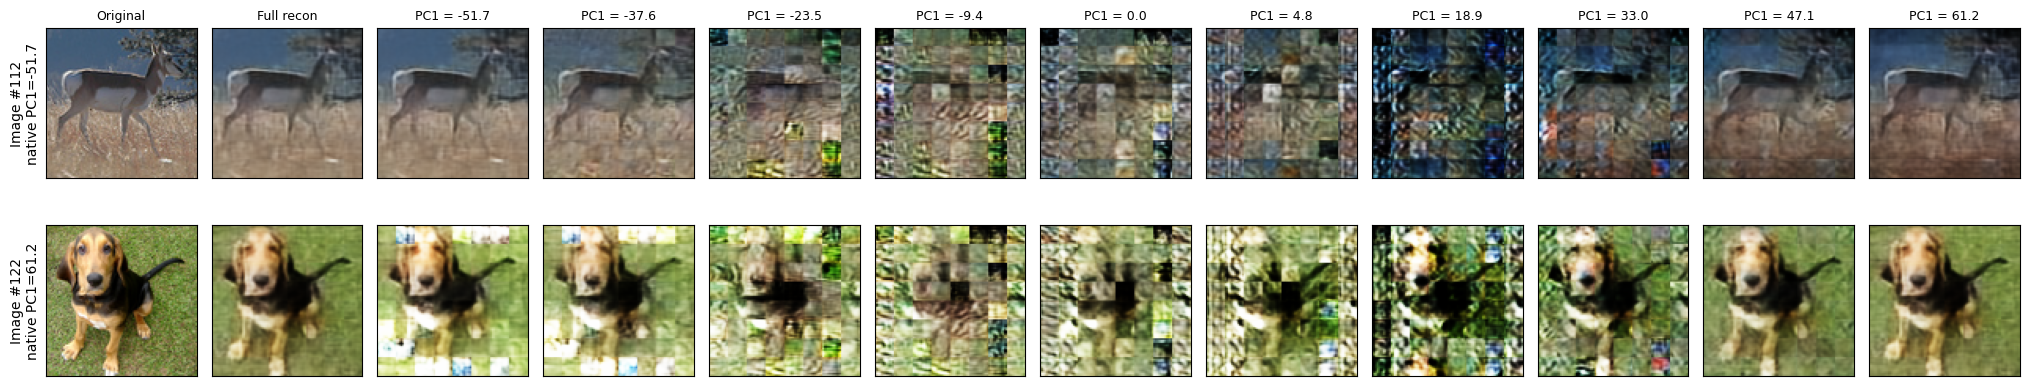

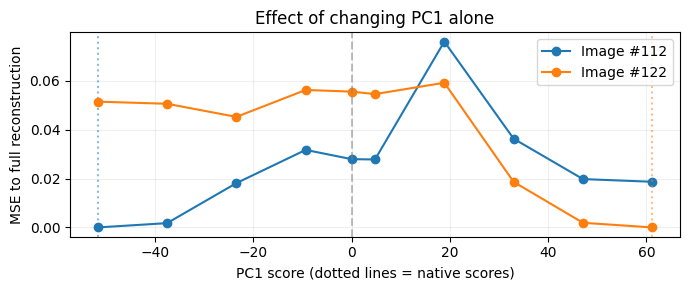

In [775]:
pc1_sweep_results = plot_pc1_sweep(
    encoder, decoder, train_dataloader, device,
    n_steps=9,
)

In [671]:
# latent stats: plot_z_dashboard
import torch
import matplotlib.pyplot as plt

@torch.no_grad()
def plot_z_dashboard(
    z,
    n_ref=256,
    sort_by="individual",   # "mean", "std", "individual"
    sort_abs=True,          # True = magnitude, False = signed
    heatmap_percentile=99,  # robust data-dependent color scaling
):
    """
    z: (B, L, D)

    sort_by:
        "mean"       -> both heatmaps use mean-based row/column ordering
        "std"        -> both heatmaps use std-based row/column ordering
        "individual" -> mean heatmap sorts by mean, std heatmap sorts by std

    sort_abs:
        Mean:
            True  -> sort by |mean|, farthest from 0 first
            False -> sort by signed mean, positive -> negative

        Std:
            True  -> sort by |std - 1|, farthest from 1 first
            False -> sort by std - 1, high std -> low std

    heatmap_percentile:
        Robust percentile used for data-dependent heatmap limits.
        Mean stays symmetric around 0.
        Std uses its own low/high percentiles.
    """

    assert sort_by in ("mean", "std", "individual")
    assert 50 < heatmap_percentile <= 100

    z = z.detach().float().cpu()
    assert z.ndim == 3, f"Expected (B, L, D), got {z.shape}"

    B, L, D = z.shape
    assert B >= 2, "Need at least B=2"

    # ------------------------------------------------------------
    # REAL STATS
    # ------------------------------------------------------------

    cell_mean = z.mean(dim=0)               # (L, D)
    cell_std = z.std(dim=0, unbiased=True)  # (L, D)

    # What gets displayed in the side/top charts
    if sort_abs:
        token_mean = cell_mean.abs().mean(dim=1)
        emb_mean = cell_mean.abs().mean(dim=0)

        token_std = (cell_std - 1).abs().mean(dim=1)
        emb_std = (cell_std - 1).abs().mean(dim=0)

    else:
        token_mean = cell_mean.mean(dim=1)
        emb_mean = cell_mean.mean(dim=0)

        token_std = (cell_std - 1).mean(dim=1)
        emb_std = (cell_std - 1).mean(dim=0)

    # ------------------------------------------------------------
    # SORT ORDERS
    # ------------------------------------------------------------

    mean_row_order = token_mean.argsort(descending=True)
    mean_col_order = emb_mean.argsort(descending=True)

    std_row_order = token_std.argsort(descending=True)
    std_col_order = emb_std.argsort(descending=True)

    if sort_by == "mean":
        mean_rows = mean_row_order
        mean_cols = mean_col_order

        std_rows = mean_row_order
        std_cols = mean_col_order

    elif sort_by == "std":
        mean_rows = std_row_order
        mean_cols = std_col_order

        std_rows = std_row_order
        std_cols = std_col_order

    else:  # individual
        mean_rows = mean_row_order
        mean_cols = mean_col_order

        std_rows = std_row_order
        std_cols = std_col_order

    # ------------------------------------------------------------
    # RANDN REFERENCE
    # ------------------------------------------------------------

    ref_token_mean = []
    ref_emb_mean = []
    ref_token_std = []
    ref_emb_std = []

    for _ in range(n_ref):
        r = torch.randn(B, L, D)

        r_mean = r.mean(dim=0)
        r_std = r.std(dim=0, unbiased=True)

        if sort_abs:
            ref_token_mean.append(r_mean.abs().mean(dim=1))
            ref_emb_mean.append(r_mean.abs().mean(dim=0))

            ref_token_std.append((r_std - 1).abs().mean(dim=1))
            ref_emb_std.append((r_std - 1).abs().mean(dim=0))

        else:
            ref_token_mean.append(r_mean.mean(dim=1))
            ref_emb_mean.append(r_mean.mean(dim=0))

            ref_token_std.append((r_std - 1).mean(dim=1))
            ref_emb_std.append((r_std - 1).mean(dim=0))

    ref_token_mean = torch.stack(ref_token_mean)
    ref_emb_mean = torch.stack(ref_emb_mean)
    ref_token_std = torch.stack(ref_token_std)
    ref_emb_std = torch.stack(ref_emb_std)

    def summarize_ref(x):
        return (
            x.mean(dim=0),
            x.quantile(0.05, dim=0),
            x.quantile(0.95, dim=0),
        )

    token_mean_ref, token_mean_lo, token_mean_hi = summarize_ref(ref_token_mean)
    emb_mean_ref, emb_mean_lo, emb_mean_hi = summarize_ref(ref_emb_mean)

    token_std_ref, token_std_lo, token_std_hi = summarize_ref(ref_token_std)
    emb_std_ref, emb_std_lo, emb_std_hi = summarize_ref(ref_emb_std)

    # ------------------------------------------------------------
    # DATA-DEPENDENT HEATMAP LIMITS
    # ------------------------------------------------------------

    q = heatmap_percentile / 100.0
    q_lo = 1.0 - q

    # Mean:
    # keep zero as the visual center, but ignore extreme outliers
    mean_hm_lim = torch.quantile(cell_mean.abs().flatten(), q).item()

    if mean_hm_lim <= 1e-12:
        mean_hm_lim = 1e-12

    mean_hm_lo = -mean_hm_lim
    mean_hm_hi = mean_hm_lim

    # Std:
    # let the actual data determine both ends of the scale.
    # This makes a collapsed 0.000-0.023 latent visibly structured,
    # while a healthy ~0.8-1.2 latent gets its own useful range.
    std_flat = cell_std.flatten()

    std_hm_lo = torch.quantile(std_flat, q_lo).item()
    std_hm_hi = torch.quantile(std_flat, q).item()

    # Std cannot be negative
    std_hm_lo = max(0.0, std_hm_lo)

    # Guard against a perfectly / nearly constant tensor
    if std_hm_hi - std_hm_lo <= 1e-12:
        pad = max(abs(std_hm_hi) * 0.01, 1e-6)
        std_hm_lo = max(0.0, std_hm_lo - pad)
        std_hm_hi = std_hm_hi + pad

    # ------------------------------------------------------------
    # FIGURE
    # ------------------------------------------------------------

    fig = plt.figure(figsize=(18, 8), constrained_layout=True)

    gs = fig.add_gridspec(
        2, 4,
        height_ratios=[1.15, 4.0],
        width_ratios=[1.2, 4.0, 1.2, 4.0],
        wspace=0.05,
        hspace=0.05,
    )

    ax_blank1 = fig.add_subplot(gs[0, 0])
    ax_emb_mean = fig.add_subplot(gs[0, 1])

    ax_blank2 = fig.add_subplot(gs[0, 2])
    ax_emb_std = fig.add_subplot(gs[0, 3])

    ax_token_mean = fig.add_subplot(gs[1, 0])
    ax_mean_hm = fig.add_subplot(gs[1, 1])

    ax_token_std = fig.add_subplot(gs[1, 2])
    ax_std_hm = fig.add_subplot(gs[1, 3])

    ax_blank1.axis("off")
    ax_blank2.axis("off")

    # ------------------------------------------------------------
    # HELPER PLOTS
    # ------------------------------------------------------------

    def plot_top_summary(ax, values, ref, lo, hi, title):
        x = torch.arange(len(values)).numpy()

        ax.bar(x, values.numpy(), color="grey", width=1.0)
        ax.plot(x, ref.numpy(), color="green", linewidth=1.5)

        ax.fill_between(
            x,
            lo.numpy(),
            hi.numpy(),
            color="yellow",
            alpha=0.25,
        )

        ax.set_title(title, fontsize=10)
        ax.set_xlim(-0.5, len(values) - 0.5)

        ax.tick_params(axis="x", labelbottom=False)
        ax.tick_params(axis="y", labelsize=8)

    def plot_side_summary(ax, values, ref, lo, hi, title):
        y = torch.arange(len(values)).numpy()

        ax.barh(y, values.numpy(), color="grey", height=1.0)
        ax.plot(ref.numpy(), y, color="green", linewidth=1.5)

        ax.fill_betweenx(
            y,
            lo.numpy(),
            hi.numpy(),
            color="yellow",
            alpha=0.25,
        )

        ax.set_title(title, fontsize=10)
        ax.set_ylim(len(values) - 0.5, -0.5)

        ax.tick_params(axis="y", labelleft=False)
        ax.tick_params(axis="x", labelsize=8)

    # ------------------------------------------------------------
    # MINI CHARTS
    # ------------------------------------------------------------

    plot_top_summary(
        ax_emb_mean,
        emb_mean[mean_cols],
        emb_mean_ref[mean_cols],
        emb_mean_lo[mean_cols],
        emb_mean_hi[mean_cols],
        "emb-mean",
    )

    plot_side_summary(
        ax_token_mean,
        token_mean[mean_rows],
        token_mean_ref[mean_rows],
        token_mean_lo[mean_rows],
        token_mean_hi[mean_rows],
        "token-mean",
    )

    plot_top_summary(
        ax_emb_std,
        emb_std[std_cols],
        emb_std_ref[std_cols],
        emb_std_lo[std_cols],
        emb_std_hi[std_cols],
        "emb-std",
    )

    plot_side_summary(
        ax_token_std,
        token_std[std_rows],
        token_std_ref[std_rows],
        token_std_lo[std_rows],
        token_std_hi[std_rows],
        "token-std",
    )

    # ------------------------------------------------------------
    # HEATMAPS
    # ------------------------------------------------------------

    mean_heatmap_sorted = cell_mean[mean_rows][:, mean_cols]
    std_heatmap_sorted = cell_std[std_rows][:, std_cols]

    im0 = ax_mean_hm.imshow(
        mean_heatmap_sorted.numpy(),
        aspect="auto",
        interpolation="nearest",
        cmap="coolwarm",
        vmin=mean_hm_lo,
        vmax=mean_hm_hi,
    )

    ax_mean_hm.set_title(
        f"mean heatmap\n"
        f"data [{cell_mean.min().item():.3f}, {cell_mean.max().item():.3f}]   "
        f"color [{mean_hm_lo:.3f}, {mean_hm_hi:.3f}]",
        fontsize=10,
    )

    ax_mean_hm.set_xlabel("Embedding dimension (sorted)")
    ax_mean_hm.set_ylabel("Latent token (sorted)")

    im1 = ax_std_hm.imshow(
        std_heatmap_sorted.numpy(),
        aspect="auto",
        interpolation="nearest",
        cmap="coolwarm",
        vmin=std_hm_lo,
        vmax=std_hm_hi,
    )

    ax_std_hm.set_title(
        f"std heatmap\n"
        f"data [{cell_std.min().item():.3f}, {cell_std.max().item():.3f}]   "
        f"color [{std_hm_lo:.3f}, {std_hm_hi:.3f}]",
        fontsize=10,
    )

    ax_std_hm.set_xlabel("Embedding dimension (sorted)")
    ax_std_hm.set_ylabel("Latent token (sorted)")

    # ------------------------------------------------------------
    # COLORBARS
    # ------------------------------------------------------------

    cbar0 = fig.colorbar(
        im0,
        ax=ax_mean_hm,
        fraction=0.046,
        pad=0.02,
    )
    cbar0.set_label("Mean")

    cbar1 = fig.colorbar(
        im1,
        ax=ax_std_hm,
        fraction=0.046,
        pad=0.02,
    )
    cbar1.set_label("Std")

    # ------------------------------------------------------------
    # TITLE
    # ------------------------------------------------------------

    sign_label = "magnitude" if sort_abs else "signed"

    fig.suptitle(
        f"Latent stats dashboard — B={B}, L={L}, D={D}\n"
        f"sort={sort_by}, {sign_label}"
        f"   |   bars=actual"
        f"   |   green=randn expected"
        f"   |   yellow=randn 5–95%"
        f"   |   heatmaps={heatmap_percentile:g}% robust scale",
        fontsize=13,
    )

    plt.show()

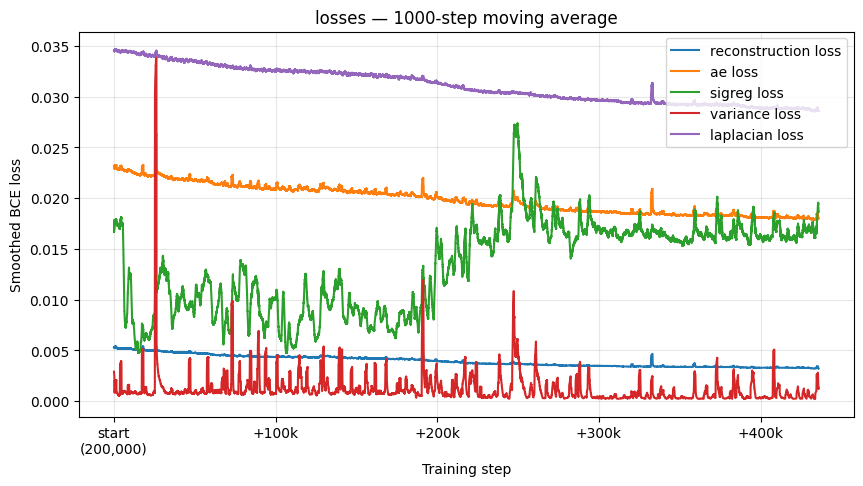

In [748]:
#plot losses
import numpy as np
from matplotlib.ticker import FuncFormatter

def moving_average(values, window=100):
    values = np.asarray(values)
    return np.convolve(values, np.ones(window) / window, mode='valid')

window = 1000

#useful for zooming in on steps
start = 200_000
# start = 236_000


end = None



plt.figure(figsize=(10, 5))


history = get_metrics_lists()

#### AE training losses
plt.plot(moving_average(history['recon_loss'], window)[start:end] , label='reconstruction loss')
plt.plot(moving_average(history['ae_loss'], window )[start:end] , label='ae loss')
plt.plot(moving_average(history['sigreg_loss'], window )[start:end] , label='sigreg loss')
plt.plot(moving_average(history['variance_loss'], window )[start:end] , label='variance loss')
plt.plot(moving_average(history['laplacian_loss'], window )[start:end] , label='laplacian loss')

# plt.plot(moving_average(history['grad_ratio'], window )[start:end] , label='sigreg/recon ratio at z')
ax = plt.gca()
ax.xaxis.set_major_formatter(FuncFormatter(
    lambda x, _: f"start\n({start:,})" if abs(x) < 1
    else f"+{x/1000:.0f}k"
))

plt.xlabel('Training step')
plt.ylabel('Smoothed BCE loss')
plt.title(f'losses — {window}-step moving average')
# plt.yscale('log')
# plt.xscale('log')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [713]:
from pathlib import Path
import torch
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

RUN_DIR = Path("training_runs")

def plot_run_comparison(
    metric="recon_loss",
    run_filter="ae_1M_align_sigreg_grad_",
    window=1000,
    start=0,
    end=None,
    include_current=True,
):
    def moving_average(values, window):
        values = np.asarray(values)

        if len(values) < window:
            return values

        return np.convolve(
            values,
            np.ones(window) / window,
            mode="valid"
        )

    histories = {}

    # -------------------------
    # archived runs from disk
    # -------------------------
    for path in sorted(RUN_DIR.glob("*.pt")):
        name = path.stem

        if run_filter not in name:
            continue

        run = torch.load(path, weights_only=False)

        # support either {"history": ...} or raw history dict
        history = run["history"] if "history" in run else run

        histories[name] = history

    # -------------------------
    # current live run
    # -------------------------
    if (
        include_current
        and current_run_name is not None
        and run_filter in current_run_name
    ):
        histories[current_run_name] = get_metrics_lists()

    if not histories:
        print(f"No runs found matching: {run_filter}")
        return

    print(f"Found {len(histories)} runs:")
    for name in histories:
        print("  ", name)

    # -------------------------
    # plot
    # -------------------------
    plt.figure(figsize=(10, 5))

    for name, history in histories.items():
        if metric not in history:
            continue

        values = moving_average(history[metric], window)

        if start >= len(values):
            continue

        y = values[start:end]
        x = np.arange(len(y))

        # leaves just: plain / sovereign / protected / reinforce
        label = name.split(run_filter, 1)[-1]

        plt.plot(x, y, label=label)

    ax = plt.gca()
    ax.xaxis.set_major_formatter(FuncFormatter(
        lambda x, _: f"start\n({start:,})" if abs(x) < 1
        else f"+{x/1000:.0f}k"
    ))

    plt.xlabel("Training step")
    plt.ylabel(f"Smoothed {metric}")
    plt.title(f"{metric} comparison — {window}-step moving average")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

Found 5 runs:
   2026-09-04_1424_ae_1M_align_sigreg_grad_plain
   2026-09-04_1505_ae_1M_align_sigreg_grad_sovereign
   2026-09-04_1546_ae_1M_align_sigreg_grad_protected
   2026-09-04_1624_ae_1M_align_sigreg_grad_reinforce
   ae_1M_align_sigreg_grad_reinforce_670e


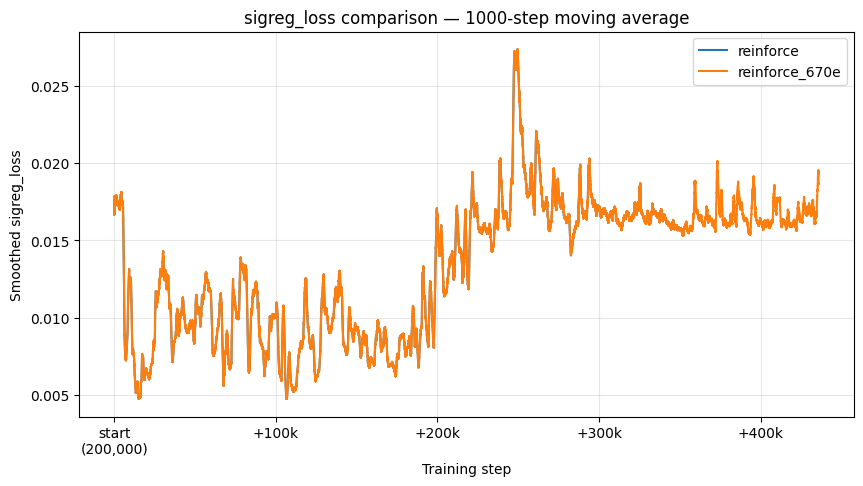

Found 5 runs:
   2026-09-04_1424_ae_1M_align_sigreg_grad_plain
   2026-09-04_1505_ae_1M_align_sigreg_grad_sovereign
   2026-09-04_1546_ae_1M_align_sigreg_grad_protected
   2026-09-04_1624_ae_1M_align_sigreg_grad_reinforce
   ae_1M_align_sigreg_grad_reinforce_670e


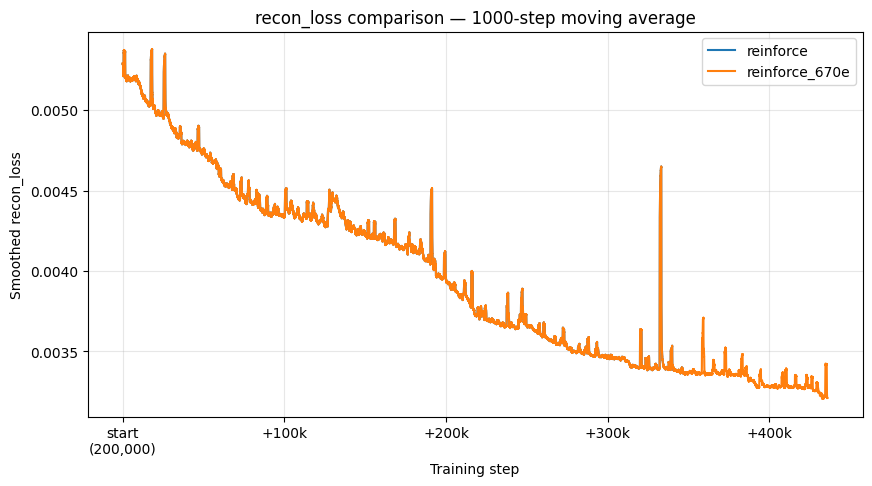

In [749]:
plot_run_comparison('sigreg_loss', start=200_000)
plot_run_comparison('recon_loss', start=200_000)

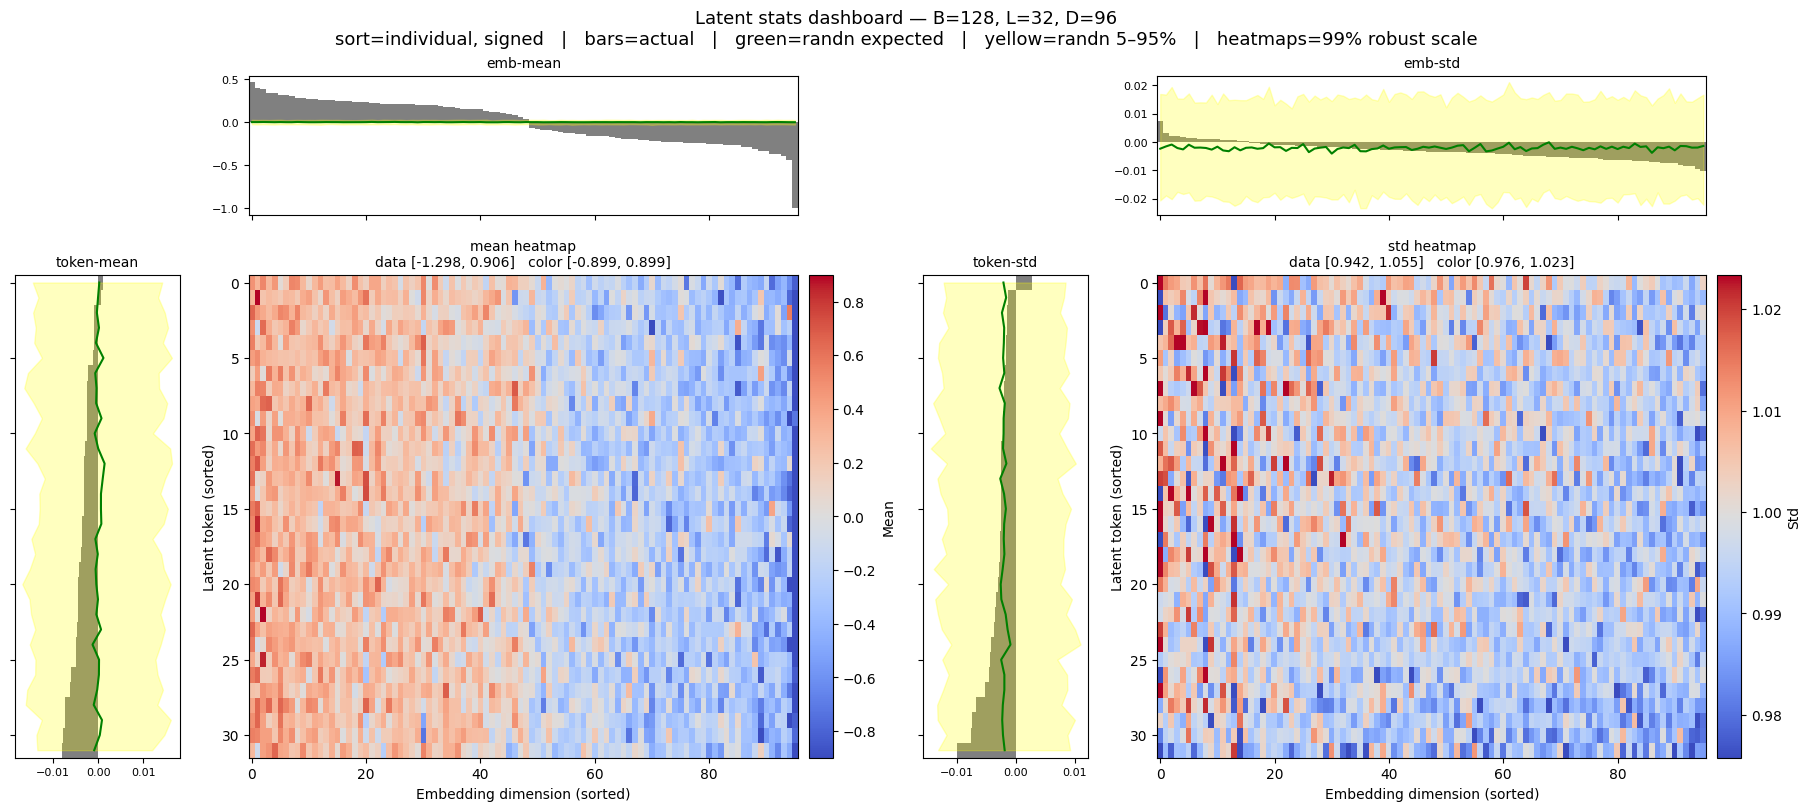

In [750]:
train_iter = iter(train_dataloader)
features, labels = next(train_iter)[:20]
features = features.to(device)
z , p, _ , _ = encoder(features)
z.shape
# Usage:

sort_by = "individual"   # "mean", "std", or "individual"
sort_abs = False  # True = magnitude, False = signed

plot_z_dashboard(
    z,
    n_ref=256,
    sort_by=sort_by, 
    sort_abs=sort_abs,     
)

In [587]:
def plot_glerp_alignment(images, steps=11):
    with torch.no_grad():
        enc = encoder(images.to(device))
        z0, z1 = enc.z, enc.z.roll(1, 0)
        ts = torch.linspace(0, 1, steps, device=device)

        align, to_z0, to_z1 = [], [], []

        for t in ts:
            zt = ((1-t)*z0 + t*z1) / torch.sqrt((1-t)**2 + t**2)
            zr = encoder(decoder(enc._replace(z=zt))).z

            cos = lambda a, b: F.cosine_similarity(a.flatten(1), b.flatten(1), dim=1).mean()
            align.append(cos(zr, zt))
            to_z0.append(cos(zr, z0))
            to_z1.append(cos(zr, z1))
        
        raw_z0 = []
        raw_z1 = []
        
        for t in ts:
            zt = ((1-t)*z0 + t*z1) / torch.sqrt((1-t)**2 + t**2)
            raw_z0.append(cos(zt, z0))
            raw_z1.append(cos(zt, z1))
            

    plt.plot(ts.cpu(), torch.stack(raw_z0).cpu(), "--", label="zt → z0")
    plt.plot(ts.cpu(), torch.stack(raw_z1).cpu(), "--", label="zt → z1")

    plt.plot(ts.cpu(), torch.stack(align).cpu(), label="zr → zt")
    plt.plot(ts.cpu(), torch.stack(to_z0).cpu(), label="zr → z0")
    plt.plot(ts.cpu(), torch.stack(to_z1).cpu(), label="zr → z1")
    plt.xlabel("glerp t")
    plt.ylabel("cosine")
    plt.ylim(-1, 1)
    plt.legend()
    plt.show()

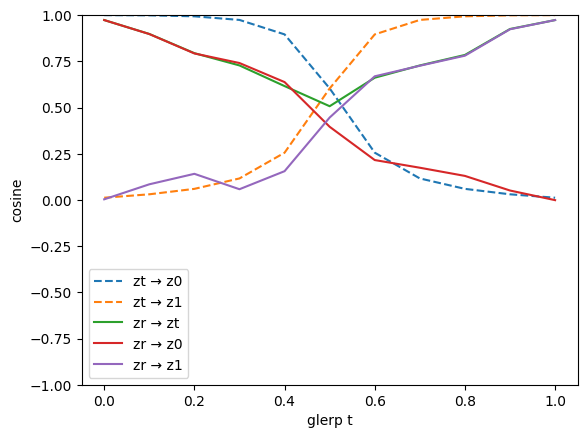

In [751]:
features, _ = next(iter(train_dataloader))
plot_glerp_alignment(features)

In [752]:
# probe: reconstruction robustness to latent perturbation
from types import SimpleNamespace

@torch.no_grad()
def plot_z_robustness():
    features, _ = next(iter(train_dataloader))
    features = features.to(device)

    enc = encoder(features)
    z = enc.z

    z_std = z.std()

    # noise std as fraction of latent std
    noise_fracs = [0.0, 0.01, 0.02, 0.05, 0.10, 0.20, 0.50]

    losses = []
    recons = []

    # use the SAME noise direction at every strength
    noise = torch.randn_like(z)

    for frac in noise_fracs:
        z_noisy = z + frac * z_std * noise

        noisy_enc = SimpleNamespace(
            z=z_noisy,
            patch_rows=enc.patch_rows,
            patch_cols=enc.patch_cols,
        )

        x_hat = decoder(noisy_enc)

        losses.append(F.mse_loss(x_hat, features).item())
        recons.append(x_hat)

    # -------------------------
    # quantitative robustness
    # -------------------------
    plt.figure(figsize=(6, 4))
    plt.plot(noise_fracs, losses, marker='o')
    plt.xlabel("noise std / latent std")
    plt.ylabel("reconstruction MSE")
    plt.title("Decoder robustness to latent noise")
    plt.grid(alpha=.25)
    plt.show()

    # -------------------------
    # visual robustness
    # -------------------------
    idx = 1

    fig, axs = plt.subplots(
        1, len(noise_fracs) + 1,
        figsize=(3 * (len(noise_fracs) + 1), 3)
    )

    x = features[idx].detach().cpu().permute(1, 2, 0)

    axs[0].imshow(x)
    axs[0].set_title("input")
    axs[0].axis("off")

    for ax, frac, recon, loss in zip(
        axs[1:], noise_fracs, recons, losses
    ):
        img = recon[idx].detach().cpu().permute(1, 2, 0)

        ax.imshow(img)
        ax.set_title(f"σ={frac:.2f}\nMSE={loss:.4f}")
        ax.axis("off")

    plt.tight_layout()
    plt.show()

    print(f"latent std: {z_std.item():.4f}")


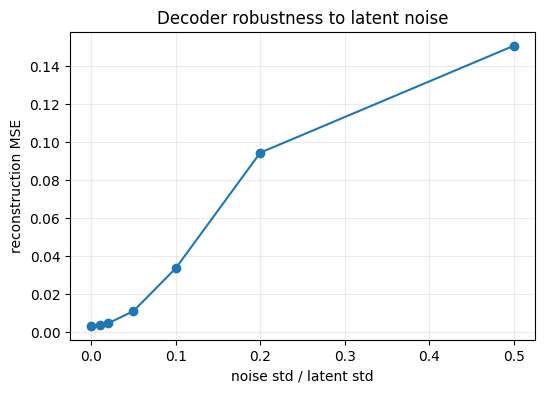

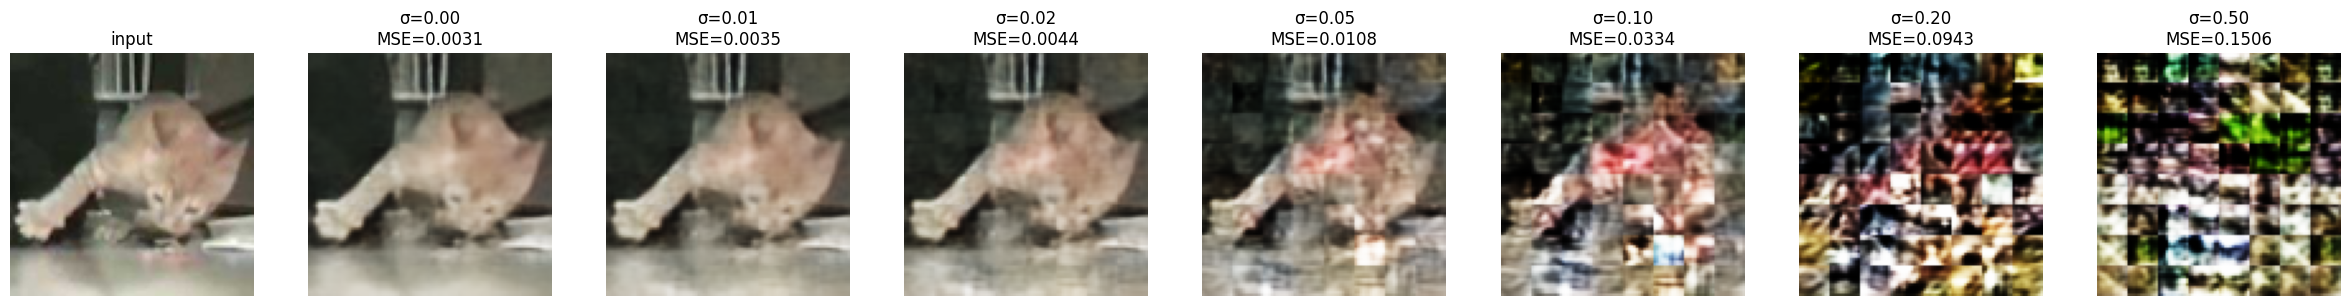

latent std: 1.0427


In [753]:

plot_z_robustness()

In [720]:
# plot latent difference-preservation loss across interpolation alpha

import copy
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
def plot_latent_geometry_interp():
     
    encoder.eval()
    decoder.eval()
    
    features, _ = next(iter(train_dataloader))
    features = features.to(device)
    
    alphas = torch.linspace(0, 1, 21, device=device)
    
    mean_retention = []
    median_retention = []
    q25_retention = []
    q75_retention = []
    
    with torch.no_grad():
    
        enc = encoder(features)
        z = enc.z
    
        # interpolation partner
        z2 = z.roll(1, dims=0)
    
        for a in alphas:
    
            # latent interpolation
            z_interp = torch.lerp(z, z2, a)
    
            # decode interpolated latent
            enc_interp = enc._replace(z=z_interp)
            x_interp = decoder(enc_interp)
    
            # encode it again
            z_rt = encoder(x_interp).z
    
            # flatten each image's whole latent
            z0 = z_interp.flatten(1)
            z1 = z_rt.flatten(1)
    
            # distances between EVERY unique pair in the batch
            d_before = torch.pdist(z0)
            d_after  = torch.pdist(z1)
    
            # fraction of original spacing preserved
            retention = d_after / (d_before + 1e-8)
    
            mean_retention.append(retention.mean().item())
            median_retention.append(retention.median().item())
            q25_retention.append(torch.quantile(retention, 0.25).item())
            q75_retention.append(torch.quantile(retention, 0.75).item())
    
    
    a = alphas.cpu().numpy()
    
    plt.figure(figsize=(9, 5))
    
    plt.plot(a, median_retention, marker='o', label='median distance retention')
    plt.plot(a, mean_retention, linestyle='--', label='mean distance retention')
    
    plt.fill_between(
        a,
        q25_retention,
        q75_retention,
        alpha=0.2,
        label='25–75% of pairs'
    )
    
    plt.axhline(1.0, linestyle=':', label='perfect distance preservation')
    
    plt.xlabel("interpolation α")
    plt.ylabel("distance after / distance before")
    plt.title("Latent spacing preserved through dec → enc")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

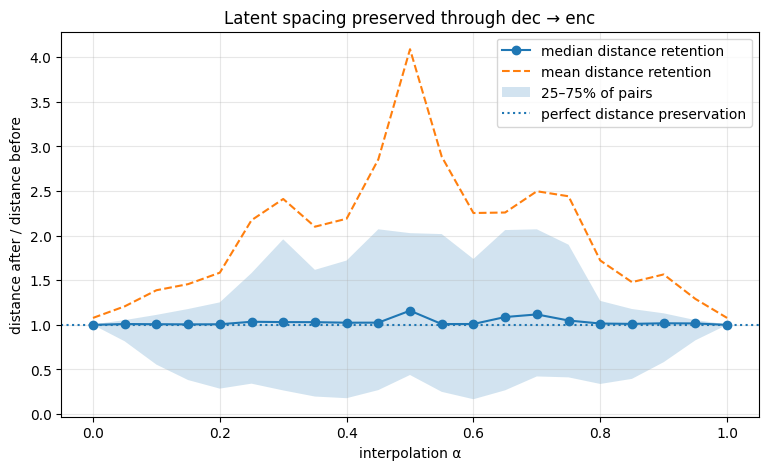

In [721]:
plot_latent_geometry_interp()

In [722]:
# how far each interpolated latent moves through dec -> enc
def plot_interp_latent_distance():
    import torch
    import matplotlib.pyplot as plt
    
    encoder.eval()
    decoder.eval()
    
    features, _ = next(iter(train_dataloader))
    features = features.to(device)
    
    alphas = torch.linspace(0, 1, 21, device=device)
    
    mean_displacement = []
    median_displacement = []
    q25_displacement = []
    q75_displacement = []
    
    with torch.no_grad():
    
        enc = encoder(features)
        z = enc.z
        z2 = z.roll(1, dims=0)
    
        for a in alphas:
    
            # interpolate
            z_interp = torch.lerp(z, z2, a)
    
            # round trip
            enc_interp = enc._replace(z=z_interp)
            x_interp = decoder(enc_interp)
            z_rt = encoder(x_interp).z
    
            # per-example relative displacement
            delta = (z_rt - z_interp).flatten(1)
            z_flat = z_interp.flatten(1)
    
            displacement = (
                delta.norm(dim=1)
                / (z_flat.norm(dim=1) + 1e-8)
            )
    
            mean_displacement.append(displacement.mean().item())
            median_displacement.append(displacement.median().item())
            q25_displacement.append(torch.quantile(displacement, 0.25).item())
            q75_displacement.append(torch.quantile(displacement, 0.75).item())
    
    
    a = alphas.cpu().numpy()
    
    plt.figure(figsize=(9, 5))
    
    plt.plot(
        a,
        median_displacement,
        marker='o',
        label='median relative displacement'
    )
    
    plt.plot(
        a,
        mean_displacement,
        linestyle='--',
        label='mean relative displacement'
    )
    
    plt.fill_between(
        a,
        q25_displacement,
        q75_displacement,
        alpha=0.2,
        label='25–75% of samples'
    )
    
    plt.axhline(0, linestyle=':')
    
    plt.xlabel("interpolation α")
    plt.ylabel("||enc(dec(z)) - z|| / ||z||")
    plt.title("Latent displacement through dec → enc")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

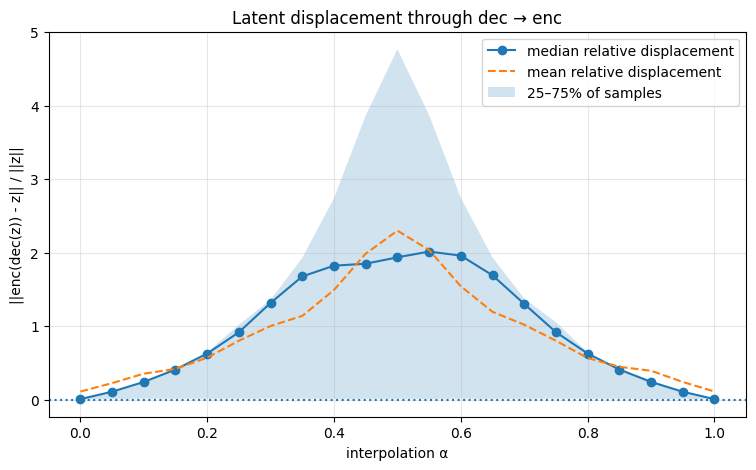

In [723]:
plot_interp_latent_distance()

In [724]:
def plot_interp_roundtrip_direction(batch=None, n_alphas=21):
    encoder.eval()
    decoder.eval()

    if batch is None:
        features, _ = next(iter(train_dataloader))
        features = features.to(device)
    else:
        features = batch.to(device)

    alphas = torch.linspace(0, 1, n_alphas, device=device)

    coherence_vals = []
    mean_disp_vals = []

    with torch.no_grad():
        enc = encoder(features)
        z = enc.z
        z2 = z.roll(1, dims=0)

        for a in alphas:
            z_interp = torch.lerp(z, z2, a)

            enc_interp = enc._replace(z=z_interp)
            x_interp = decoder(enc_interp)
            z_rt = encoder(x_interp).z

            delta = (z_rt - z_interp).flatten(1)

            # how large the average displacement is
            mean_disp = delta.norm(dim=1).mean()

            # how aligned the displacement vectors are
            # 1 = same direction, 0 = directions cancel out
            coherence = (
                delta.mean(dim=0).norm()
                / (delta.norm(dim=1).mean() + 1e-8)
            )

            mean_disp_vals.append(mean_disp.item())
            coherence_vals.append(coherence.item())

    a = alphas.cpu().numpy()

    plt.figure(figsize=(9, 5))
    plt.plot(a, coherence_vals, marker='o')
    plt.xlabel("interpolation α")
    plt.ylabel("||mean(Δz)|| / mean(||Δz||)")
    plt.title("Alignment of dec → enc latent displacement")
    plt.ylim(0, 1.05)
    plt.grid(alpha=0.3)
    plt.show()

    return {
        "alphas": a,
        "coherence": coherence_vals,
        "mean_displacement": mean_disp_vals,
    }

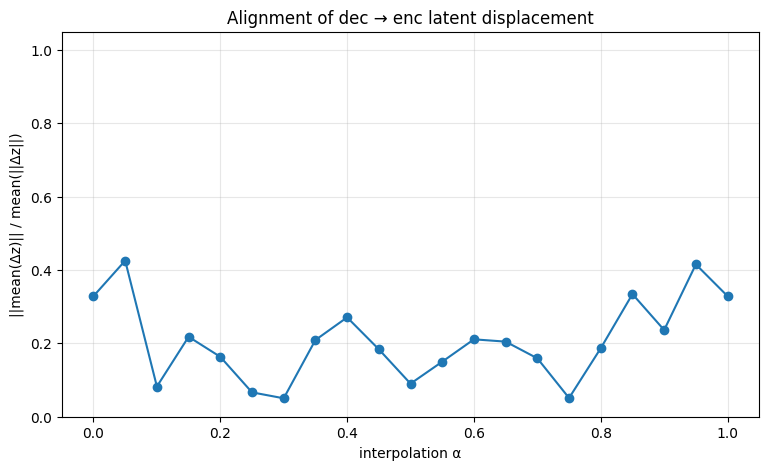

{'alphas': array([0.        , 0.05      , 0.1       , 0.15      , 0.2       ,
        0.25      , 0.3       , 0.35      , 0.4       , 0.45000002,
        0.5       , 0.55      , 0.6       , 0.65      , 0.7       ,
        0.75      , 0.8       , 0.85      , 0.9       , 0.95      ,
        1.        ], dtype=float32),
 'coherence': [0.3288422226905823,
  0.4256809949874878,
  0.08234173059463501,
  0.218043252825737,
  0.16336682438850403,
  0.06646736711263657,
  0.05023893341422081,
  0.2091497778892517,
  0.27093788981437683,
  0.18388745188713074,
  0.09017530828714371,
  0.1500791609287262,
  0.21106503903865814,
  0.2047949731349945,
  0.15926086902618408,
  0.05101708695292473,
  0.18679490685462952,
  0.3344452381134033,
  0.23644301295280457,
  0.41541534662246704,
  0.3288422226905823],
 'mean_displacement': [4.711305618286133,
  10.220942497253418,
  17.035423278808594,
  20.72969627380371,
  27.15057945251465,
  34.026649475097656,
  36.14667892456055,
  35.69872283935547,
 

In [725]:
plot_interp_roundtrip_direction()

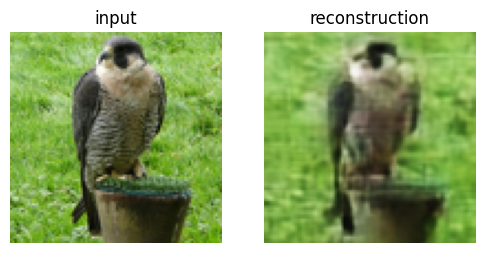

In [726]:
render_reconstruction()

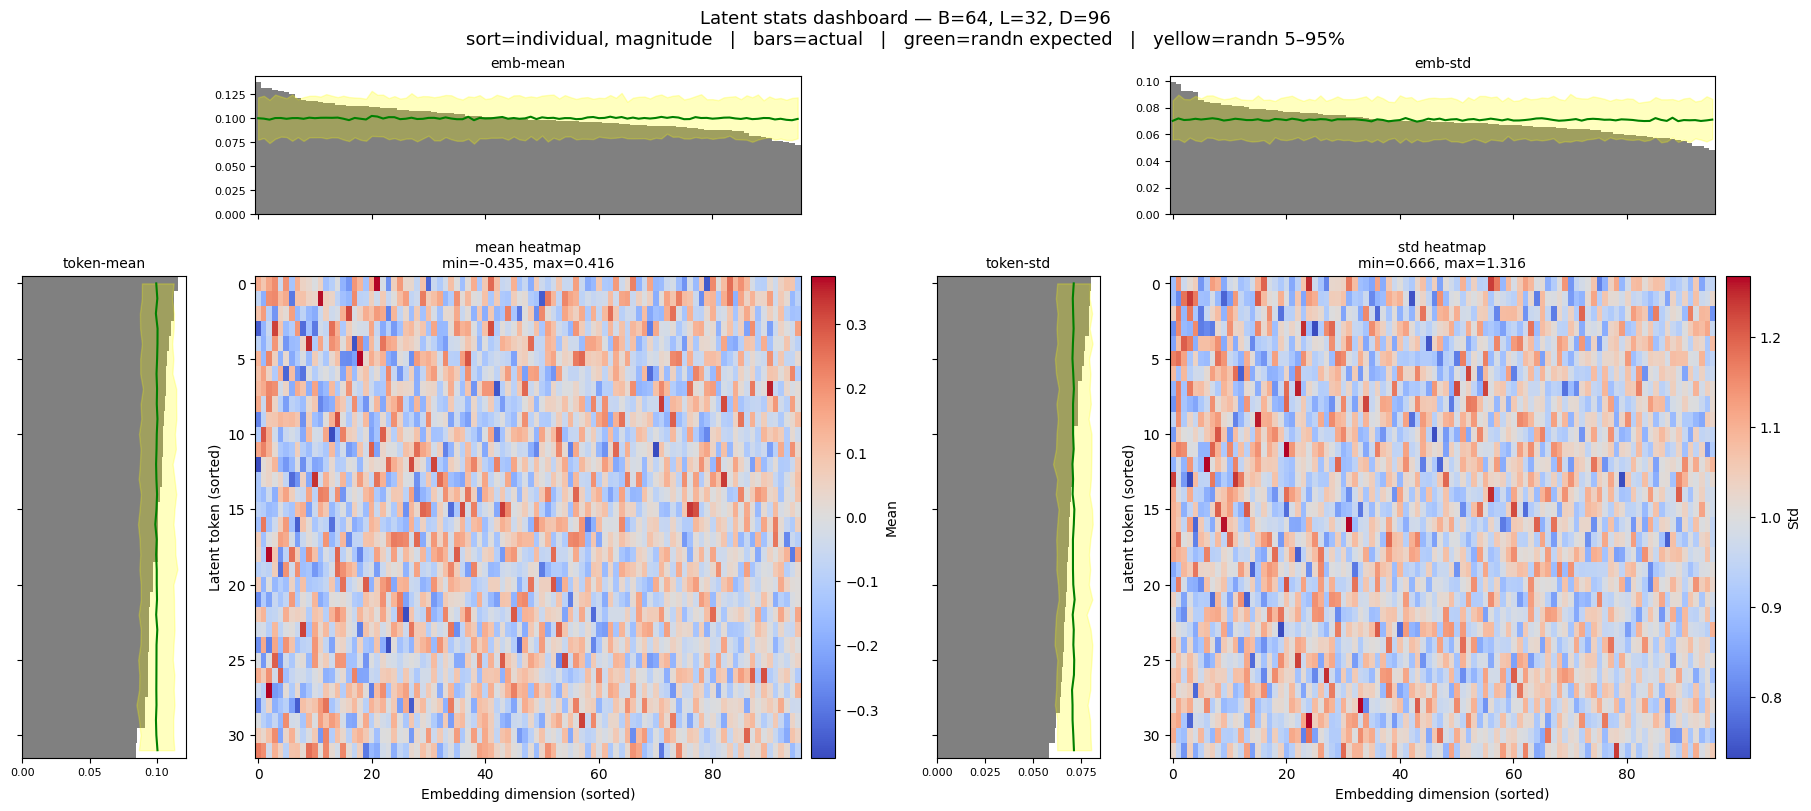

In [1289]:
#reference good (randn gaussian) z

with torch.no_grad():
    z_prior = torch.randn_like(z)
    z_prior = encoder.out_norm(
        z_prior.flatten(1)
    ).reshape_as(z)

    plot_z_dashboard(z_prior)

In [ ]:
#######trace gradient magnitudes

# features = next(iter(train_dataloader))[0].to(device)

# #forward
# x_hat = decoder(*encoder(features))
# x_hat.retain_grad()

# loss = F.mse_loss(features, x_hat)

# #zero grad
# optimizer.zero_grad()

# #backward
# loss.backward()
# # list model parameters
# params = list(encoder.named_parameters())+list(decoder.named_parameters())

# prev_grad = 0.000001
# for i, p in enumerate(params):
#     parts = p[0].split('.')
#     name = '.'.join([parts[0], *parts[-2:]] )
#     grad = p[1].grad.abs().mean()
#     grad_delta = prev_grad/grad
#     print(f'{name:40s} grad mean {grad:.4f}    prev_grad/grad {grad_delta:.4f}')
#     prev_grad = grad

In [479]:

import os
import torch

name = 'autoencoder_checkpoint_1M_100k_baseline.pt'

In [480]:
#load models

checkpoint = torch.load(
    "checkpoints/" + name,
    map_location=device,
    weights_only=True,
)

encoder.load_state_dict(checkpoint["encoder"])
decoder.load_state_dict(checkpoint["decoder"])
discriminator.load_state_dict(checkpoint["discriminator"])

print("Checkpoint loaded")

Checkpoint loaded


In [315]:
## save models


os.makedirs("checkpoints", exist_ok=True)

checkpoint_path = "checkpoints/" + name

torch.save({
    "encoder": encoder.state_dict(),
    "decoder": decoder.state_dict(),
    "discriminator": discriminator.state_dict(),
}, checkpoint_path)

print(f"Saved checkpoint to {checkpoint_path}")

Saved checkpoint to checkpoints/autoencoder_checkpoint_1M_100k_baseline.pt


In [ ]:
# ANIMATION TRAINING LOOP
############################################################################
############################# ANIM TRAINING LOOP ###########################
############################################################################
max_steps = 30_000

lossi = []
lossi_recon = []
lossi_d_real = []
lossi_d_fake = []
lossi_adv = []

#Animation settings
fps = 30
seconds = 30

total_frames = fps*seconds
steps_per_snapshot = max_steps//total_frames

#for plotting randn generations
fixed_reconstruction_targets = (
    next(iter(train_dataloader))[0][:4]
    .detach()
    .clone()
)


encoder.train()
decoder.train()
discriminator.train()

train_loss = get_split_loss('train')
test_loss = get_split_loss('test')

print(f'START TRAINING LOOP train loss:{train_loss:.5f}  test loss: {test_loss:.5f}')

for i in range(max_steps):
    #train discriminator

    try:
        images, _ = next(train_iter)
    except StopIteration:
        train_iter = iter(train_dataloader)
        images, _ = next(train_iter)

    train_step(images)

    if i % steps_per_snapshot == 0:
        with torch.no_grad():
            plot_training_snapshot(
                recon_targets = fixed_reconstruction_targets,
                step=i,
                total_steps=max_steps,
                save_path=f"frames/frame_{i:06d}.png",
                show=False,
            )
            
        train_loss = get_split_loss('train')
        test_loss = get_split_loss('test')
        print(f'step:{i}  train loss:{train_loss:.5f}  test loss: {test_loss:.5f}')

        assert encoder.training
        assert decoder.training
        assert discriminator.training